# Imports

## Import the folder for compatibility (if running local)

In [1]:
import os
import sys

project_root = "Incremental-Learning-MycroftMinds"
cwd = os.path.abspath(os.getcwd())
while True:
    if os.path.basename(cwd) == project_root:
        if cwd not in sys.path:
            sys.path.insert(0, cwd)
        break
    parent = os.path.dirname(cwd)
    if parent == cwd:
        raise FileNotFoundError(f"Project root '{project_root}' not found in any parent directory.")
    cwd = parent

## Import external libs and internal models

In [2]:
import time
import pandas as pd

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.evaluation.metrics import all_time_aggregation_metrics
from src.evaluation.visualization import plot_hourly_predictions
from src.evaluation.training import all_valid_splits_seq_fit_predict, test_set_seq_fit_predict

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from river.forest import ARFRegressor
from river.tree import HoeffdingTreeRegressor
from src.evaluation.baseline import PreviousValueRegressor, SeasonalMeanRegressor
from src.trees import fastodt
from src.bagging import ARFRegressorFODT
from src.boosting import IncubationBoost
from src.ensemble_methods.IncubationBoostElastic import IncubationBoostElastic
from src.ensemble_methods import elasticGBDT

import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

# Download the splitted data

In [3]:
# check you data dir and file prefixes
data_dir = '../../data/other_data/'

## Pick the hourly granularity data
- WFV, train+=28 (train set increasing), validation=28, hourly granularity

## Evaluation Settings

In [4]:
DATA_FREQUENCY = 'H'  # 1-Hour frequency
FORECAST_HORIZON = '1h'  # 1-Hour forecast horizon
SPIKE_PROMINENCE = 5  # Prominence for spike detection, adjusted after EDA
USE_RESIDUAL = True

In [5]:
# Measure loading time
start_time = time.time()

# Load data

train, valid, test = load_dataset(data_dir=data_dir, prefix='od_aq_hour_wfv', use_numpy=True)

ALL_FEATURES = ['time', 'device_id', 'hour', 'weekday', 'month', 'pm2.5_lag_1h', 'pm2.5_lag_2h',
                'pm2.5_lag_3h', 'pm2.5_lag_4h', 'pm2.5_lag_24h', 'TEMP_lag_1h', 'TEMP_lag_2h',
                'TEMP_lag_3h', 'TEMP_lag_4h', 'TEMP_lag_24h', 'DEWP_lag_1h', 'DEWP_lag_2h',
                'DEWP_lag_3h', 'DEWP_lag_4h', 'DEWP_lag_24h', 'Iws_lag_1h', 'Iws_lag_2h',
                'Iws_lag_3h', 'Iws_lag_4h', 'Iws_lag_24h']


loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

[INFO] Loading train data...
[INFO] Train data loaded: 19 samples
[INFO] Loading valid data...
[INFO] Valid data loaded: 19 samples
[INFO] Loading test data...
[INFO] Test data loaded: 2 samples
Data loaded in 0.02 minutes


## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [6]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

Training data: 19 splits
Validation data: 19 splits
First train split shape: X=(672, 25), y=(672,)
First valid split shape: X=(672, 25), y=(672,)

Memory usage:
Train: 25.33 MB
Valid: 2.54 MB
Test: 1.39 MB
Total: 29.26 MB


# WFV Model Evaluation
(train+valid WFV)
- (1) `train[0]` vs `valid[0]`
- (2) `train[1]` vs `valid[1]`
- ...
- (n) `train[n]` vs `valid[n]`

, where: 
$$ train[1] = train[0]+valid[0] $$
$$...$$
$$ train[n] = train[0]+valid[0]+valid[1]+...+valid[n-1] $$

### Baseline model (seasonal averages)

In [7]:
update_freq = "14D"
bl_mean = SeasonalMeanRegressor
bl_mean_params = {}

In [8]:
bl_mean_train_period_predictions, bl_mean_valid_period_predictions,\
bl_mean_train_period_metrics, bl_mean_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_mean,
    model_params=bl_mean_params,
    train=train,
    valid=valid,
    incremental=False,
    use_residuals=USE_RESIDUAL,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/19 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2010-01-02 02:00:00+01:00 to 2010-01-30 00:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2010-01-30 01:00:00+01:00 to 2010-02-13 01:00:00+01:00

-------------------------

Retraining model on data from 2010-01-02 02:00:00+01:00 to 2010-02-13 01:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2010-02-13 02:00:00+01:00 to 2010-02-27 00:00:00+01:00

-------------------------
Model's memory usage: 0.024628 MB
Metrics for Device: const | Period: 2010-01-30 01:00:00+01:00 - 2010-02-27 00:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 55.3924
	MAE: 20.0382
	MAPE: 34.5824%

Directional Metrics:
	Directional Accuracy: 53.0551%
	First-Diff Correlation: -0.5296

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.2000
		Recall: 0.1429
		F1: 0.1667

Delayed Detection (del

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2010-01-02 02:00:00+01:00 to 2010-02-27 00:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2010-02-27 01:00:00+01:00 to 2010-03-13 01:00:00+01:00

-------------------------

Retraining model on data from 2010-01-02 02:00:00+01:00 to 2010-03-13 01:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2010-03-13 02:00:00+01:00 to 2010-03-27 00:00:00+01:00

-------------------------
Model's memory usage: 0.024490 MB
Metrics for Device: const | Period: 2010-02-27 01:00:00+01:00 - 2010-03-27 00:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 53.0279
	MAE: 20.2833
	MAPE: 29.2193%

Directional Metrics:
	Directional Accuracy: 56.1848%
	First-Diff Correlation: -0.1264

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.2000
		Recall: 0.2000
		F1: 0.2000

Delayed Detection (del

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (29 outputs left out)

Processing devices in split 17:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2010-01-02 02:00:00+01:00 to 2011-05-21 01:00:00+02:00

Time: 0.01 seconds
Predicting for chunk from 2011-05-21 02:00:00+02:00 to 2011-06-04 02:00:00+02:00

-------------------------

Retraining model on data from 2010-01-02 02:00:00+01:00 to 2011-06-04 02:00:00+02:00

Time: 0.01 seconds
Predicting for chunk from 2011-06-04 03:00:00+02:00 to 2011-06-18 01:00:00+02:00

-------------------------
Model's memory usage: 0.024231 MB
Metrics for Device: const | Period: 2011-05-21 02:00:00+02:00 - 2011-06-18 01:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 20.5224
	MAE: 13.3707
	MAPE: 25.1971%

Directional Metrics:
	Directional Accuracy: 53.2042%
	First-Diff Correlation: -0.0647

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (del

Processing devices in split 18:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2010-01-02 02:00:00+01:00 to 2011-06-18 01:00:00+02:00

Time: 0.01 seconds
Predicting for chunk from 2011-06-18 02:00:00+02:00 to 2011-07-02 02:00:00+02:00

-------------------------

Retraining model on data from 2010-01-02 02:00:00+01:00 to 2011-07-02 02:00:00+02:00

Time: 0.01 seconds
Predicting for chunk from 2011-07-02 03:00:00+02:00 to 2011-07-16 01:00:00+02:00

-------------------------
Model's memory usage: 0.024223 MB
Metrics for Device: const | Period: 2011-06-18 02:00:00+02:00 - 2011-07-16 01:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 23.5352
	MAE: 14.2558
	MAPE: 17.5147%

Directional Metrics:
	Directional Accuracy: 50.8197%
	First-Diff Correlation: 0.1373

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delt

#### Results

In [9]:
print("\n\nValid period metrics:")
bl_mean_all_time_valid_metrics = all_time_aggregation_metrics(bl_mean_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 26.7387 ± 10.2918
	MAE: 14.7764 ± 3.0249
	MAPE: 25.3649% ± 5.2798%

	Directional Metrics:
		Directional Accuracy: 53.0551% ± 2.9810%
		First-Diff Correlation: 0.0632 ± 0.2033

	Immediate Detection (delta=0):
		Spike Precision: 0.0513 ± 0.1231
		Spike Recall: 0.0506 ± 0.1227
		Spike F1: 0.0509 ± 0.1229
		Drop Precision: 0.0645 ± 0.0887
		Drop Recall: 0.0599 ± 0.0836
		Drop F1: 0.0618 ± 0.0855

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.7869 ± 0.3124
		Spike Recall: 0.7824 ± 0.2974
		Spike F1: 0.7820 ± 0.3029
		Drop Precision: 0.3873 ± 0.3024
		Drop Recall: 0.3408 ± 0.2904
		Drop F1: 0.3577 ± 0.2929
Daily Metrics:
	RMSE: 97.1590 ± 34.4238
	MAE: 71.0726 ± 25.0760
	MAPE: 5.5741% ± 4.1278%

	Directional Metrics:
		Directional Accuracy: 97.5564% ± 2.8507%
		First-Diff Correlation: 0.9948 ± 0.0024

	Immediate Detection (delta=0):

#### Validation plots

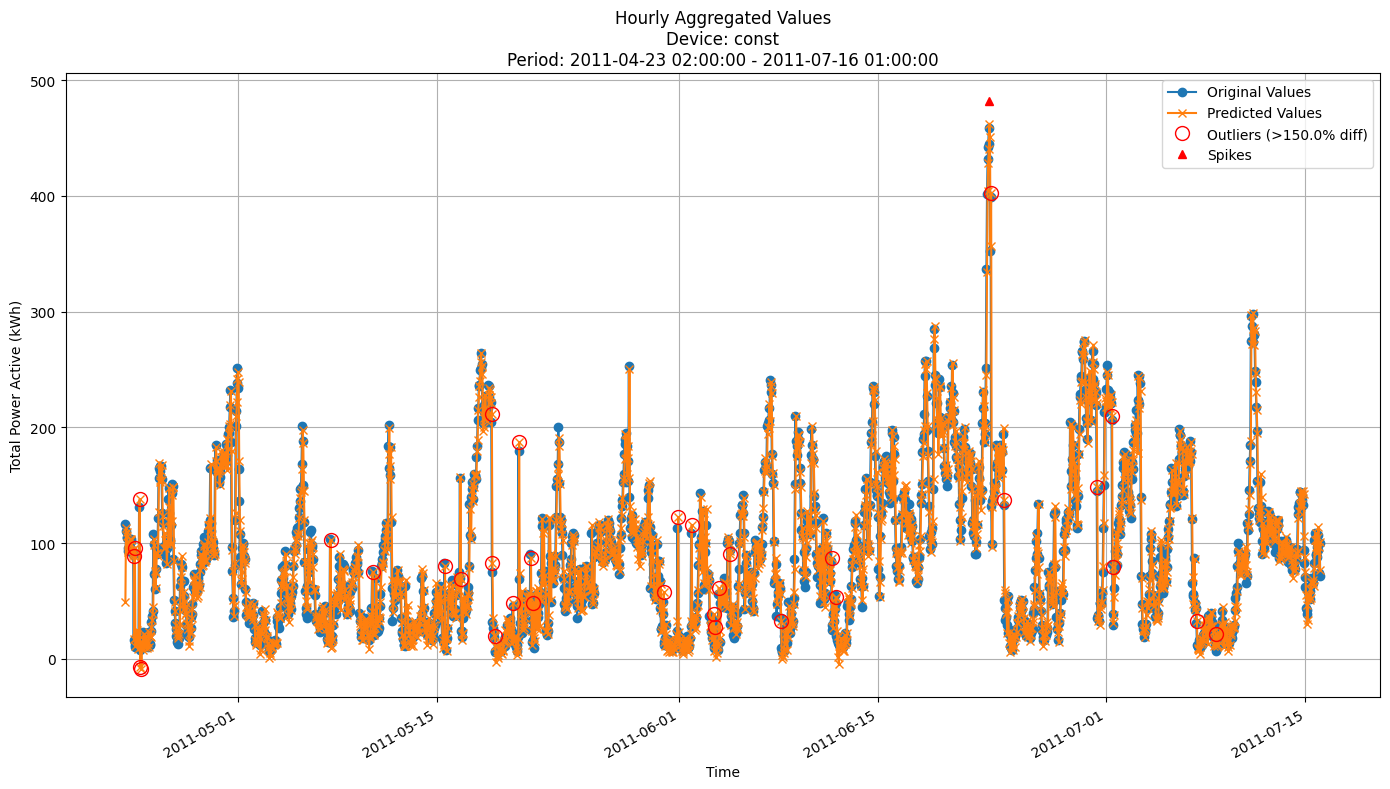


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 21.8891
MAE: 13.2449
MAPE: 23.8841%

Directional Metrics:
Directional Accuracy: 52.0099%
First-Diff Correlation: 0.0162

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [10]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in bl_mean_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_mean_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_mean_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### Baseline model (predict previous value)

In [11]:
update_freq = "1H"
bl_prev = PreviousValueRegressor
bl_prev_params = {'is_residual': USE_RESIDUAL}

In [12]:
bl_prev_train_period_predictions, bl_prev_valid_period_predictions,\
bl_prev_train_period_metrics, bl_prev_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_prev,
    model_params=bl_prev_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/19 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2010-01-30 00:00:00+01:00
Model's memory usage: 0.000511 MB
Metrics for Device: const | Period: 2010-01-30 01:00:00+01:00 - 2010-02-27 00:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 54.3306
	MAE: 16.8461
	MAPE: 23.3726%

Directional Metrics:
	Directional Accuracy: 52.1610%
	First-Diff Correlation: -0.5406

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
-------------------------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2010-02-27 00:00:00+01:00
Model's memory usage: 0.000504 MB
Metrics for Device: const | Period: 2010-02-27 01:00:00+01:00 - 2010-03-27 00:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 51.1602
	MAE: 16.7575
	MAPE: 21.8537%

Directional Metrics:
	Directional Accuracy: 50.9687%
	First-Diff Correlation: -0.1320

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
-------------------------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (29 outputs left out)

Processing devices in split 17:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2011-05-21 01:00:00+02:00
Model's memory usage: 0.000381 MB
Metrics for Device: const | Period: 2011-05-21 02:00:00+02:00 - 2011-06-18 01:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 20.0861
	MAE: 12.9179
	MAPE: 23.2272%

Directional Metrics:
	Directional Accuracy: 49.6274%
	First-Diff Correlation: -0.0600

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
-------------------------------------------------

Processing devices in split 18:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2011-06-18 01:00:00+02:00
Model's memory usage: 0.000374 MB
Metrics for Device: const | Period: 2011-06-18 02:00:00+02:00 - 2011-07-16 01:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 23.0168
	MAE: 13.6682
	MAPE: 16.2816%

Directional Metrics:
	Directional Accuracy: 49.7765%
	First-Diff Correlation: 0.1482

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------

#### Results

In [13]:
print("\n\nValid period metrics:")
bl_prev_all_time_valid_metrics = all_time_aggregation_metrics(bl_prev_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 26.0495 ± 10.2035
	MAE: 13.6488 ± 2.8340
	MAPE: 20.8362% ± 3.8254%

	Directional Metrics:
		Directional Accuracy: 51.4001% ± 2.6764%
		First-Diff Correlation: 0.0635 ± 0.2086

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 1.0000 ± 0.0000
		Spike Recall: 1.0000 ± 0.0000
		Spike F1: 1.0000 ± 0.0000
		Drop Precision: 0.8947 ± 0.3069
		Drop Recall: 0.8947 ± 0.3069
		Drop F1: 0.8947 ± 0.3069
Daily Metrics:
	RMSE: 95.2831 ± 35.1630
	MAE: 68.8294 ± 25.5789
	MAPE: 5.1423% ± 3.7609%

	Directional Metrics:
		Directional Accuracy: 97.7444% ± 2.6450%
		First-Diff Correlation: 0.9951 ± 0.0024

	Immediate Detection (delta=0):

#### Validation plots

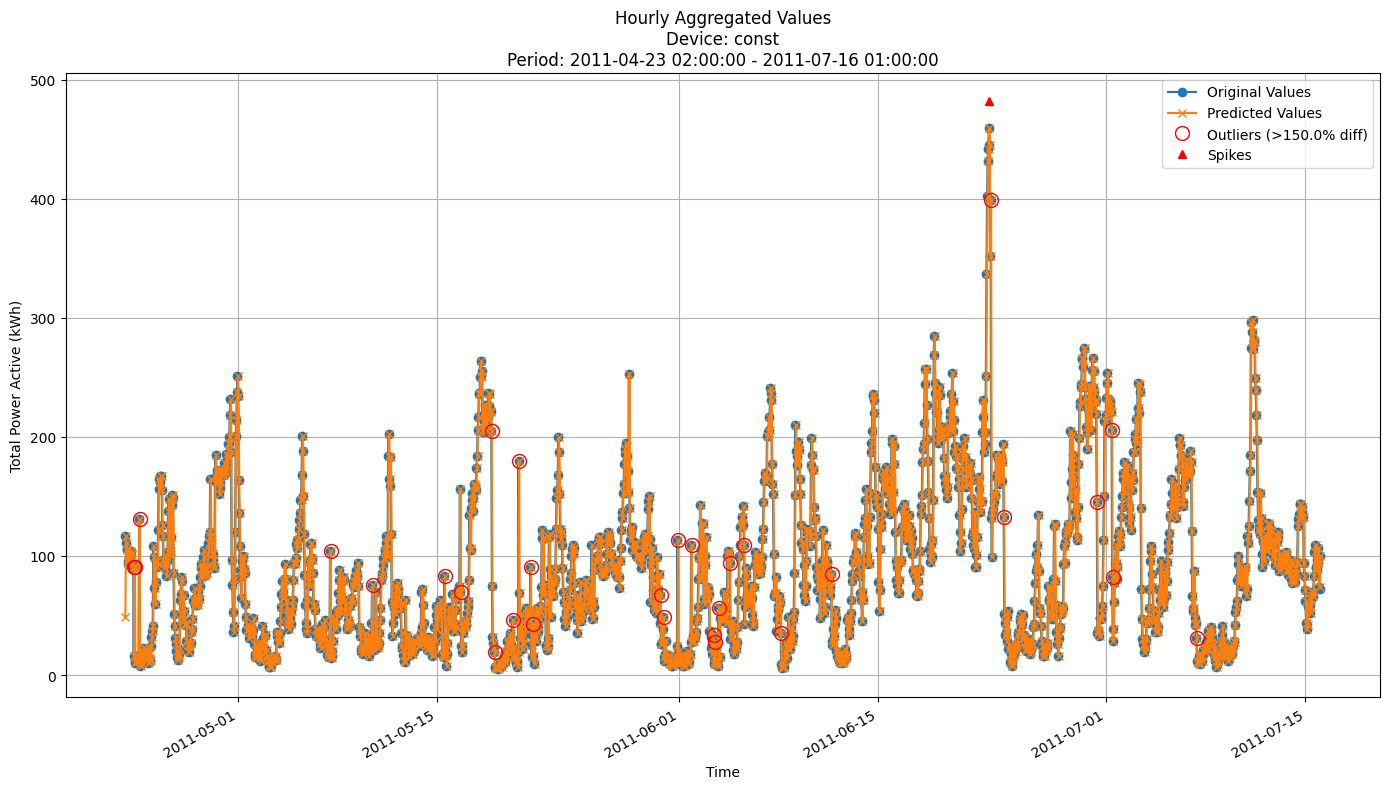


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 21.4364
MAE: 12.7332
MAPE: 21.6737%

Directional Metrics:
Directional Accuracy: 50.8189%
First-Diff Correlation: 0.0216

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [14]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in bl_prev_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_prev_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_prev_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### GBDT

In [15]:
update_freq = "14D"  # Update the model every 14 days

gbdt = GradientBoostingRegressor
gbdt_params = {'n_estimators': 25, 
               'learning_rate': 0.01, 
               'max_depth': 3, 
               'subsample': 1.0, 
               'random_state': 42}

In [16]:
gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=gbdt, 
    model_params=gbdt_params, 
    train=train, 
    valid=valid, 
    incremental=False,
    use_residuals=USE_RESIDUAL,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/19 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2010-01-02 02:00:00+01:00 to 2010-01-30 00:00:00+01:00

Time: 0.07 seconds
Predicting for chunk from 2010-01-30 01:00:00+01:00 to 2010-02-13 01:00:00+01:00

-------------------------

Retraining model on data from 2010-01-02 02:00:00+01:00 to 2010-02-13 01:00:00+01:00

Time: 0.08 seconds
Predicting for chunk from 2010-02-13 02:00:00+01:00 to 2010-02-27 00:00:00+01:00

-------------------------
Model's memory usage: 0.007675 MB
Metrics for Device: const | Period: 2010-01-30 01:00:00+01:00 - 2010-02-27 00:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 54.1715
	MAE: 16.8675
	MAPE: 23.1358%

Directional Metrics:
	Directional Accuracy: 52.9061%
	First-Diff Correlation: -0.5341

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1429
		Recall: 0.1429
		F1: 0.1429
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (del

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2010-01-02 02:00:00+01:00 to 2010-02-27 00:00:00+01:00

Time: 0.10 seconds
Predicting for chunk from 2010-02-27 01:00:00+01:00 to 2010-03-13 01:00:00+01:00

-------------------------

Retraining model on data from 2010-01-02 02:00:00+01:00 to 2010-03-13 01:00:00+01:00

Time: 0.12 seconds
Predicting for chunk from 2010-03-13 02:00:00+01:00 to 2010-03-27 00:00:00+01:00

-------------------------
Model's memory usage: 0.007599 MB
Metrics for Device: const | Period: 2010-02-27 01:00:00+01:00 - 2010-03-27 00:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 50.7893
	MAE: 16.7086
	MAPE: 21.8783%

Directional Metrics:
	Directional Accuracy: 51.1177%
	First-Diff Correlation: -0.1198

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.1667
		Recall: 0.2000
		F1: 0.1818

Delayed Detection (del

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (29 outputs left out)

Processing devices in split 17:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2010-01-02 02:00:00+01:00 to 2011-05-21 01:00:00+02:00

Time: 0.73 seconds
Predicting for chunk from 2011-05-21 02:00:00+02:00 to 2011-06-04 02:00:00+02:00

-------------------------

Retraining model on data from 2010-01-02 02:00:00+01:00 to 2011-06-04 02:00:00+02:00

Time: 0.76 seconds
Predicting for chunk from 2011-06-04 03:00:00+02:00 to 2011-06-18 01:00:00+02:00

-------------------------
Model's memory usage: 0.006912 MB
Metrics for Device: const | Period: 2011-05-21 02:00:00+02:00 - 2011-06-18 01:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 20.0705
	MAE: 12.8982
	MAPE: 23.2327%

Directional Metrics:
	Directional Accuracy: 49.7765%
	First-Diff Correlation: -0.0601

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (del

Processing devices in split 18:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2010-01-02 02:00:00+01:00 to 2011-06-18 01:00:00+02:00

Time: 0.79 seconds
Predicting for chunk from 2011-06-18 02:00:00+02:00 to 2011-07-02 02:00:00+02:00

-------------------------

Retraining model on data from 2010-01-02 02:00:00+01:00 to 2011-07-02 02:00:00+02:00

Time: 0.78 seconds
Predicting for chunk from 2011-07-02 03:00:00+02:00 to 2011-07-16 01:00:00+02:00

-------------------------
Model's memory usage: 0.006912 MB
Metrics for Device: const | Period: 2011-06-18 02:00:00+02:00 - 2011-07-16 01:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 22.9238
	MAE: 13.6158
	MAPE: 16.2266%

Directional Metrics:
	Directional Accuracy: 49.7765%
	First-Diff Correlation: 0.1482

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delt

#### Results

In [17]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.2486 ± 0.0612
# 	MAE: 0.1594 ± 0.0516
# 	MAPE: 33.4958% ± 5.3587%

# 	Directional Metrics:
# 		Directional Accuracy: 62.4754% ± 7.1041%
# 		First-Diff Correlation: 0.3821 ± 0.0970

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.1544 ± 0.1193
# 		Spike Recall: 0.1617 ± 0.1297
# 		Spike F1: 0.1577 ± 0.1238
# 		Drop Precision: 0.1459 ± 0.0857
# 		Drop Recall: 0.1534 ± 0.0909
# 		Drop F1: 0.1493 ± 0.0879

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4691 ± 0.2714
# 		Spike Recall: 0.4908 ± 0.2907
# 		Spike F1: 0.4788 ± 0.2795
# 		Drop Precision: 0.2117 ± 0.1062
# 		Drop Recall: 0.2201 ± 0.1161
# 		Drop F1: 0.2153 ± 0.1100



Train period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 31.3214 ± 4.9132
	MAE: 13.8443 ± 0.5404
	MAPE: 19.3635% ± 0.9348%

	Directional Metrics:
		Directional Accuracy: 51.6211% ± 0.3223%
		First-Diff Correlation: -0.1138 ± 0.1213

	Immediate Detection (delta=0):
		Spike Precision: 0.0044 ± 0.0186
		Spike Recall: 0.0044 ± 0.0186
		Spike F1: 0.0044 ± 0.0186
		Drop Precision: 0.0043 ± 0.0138
		Drop Recall: 0.0043 ± 0.0138
		Drop F1: 0.0043 ± 0.0138

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 1.0000 ± 0.0000
		Spike Recall: 0.9946 ± 0.0183
		Spike F1: 0.9972 ± 0.0095
		Drop Precision: 0.9868 ± 0.0558
		Drop Recall: 0.9763 ± 0.0577
		Drop F1: 0.9814 ± 0.0557
Daily Metrics:
	RMSE: 99.4228 ± 8.0090
	MAE: 70.8124 ± 4.5994
	MAPE: 3.9390% ± 0.5093%

	Directional Metrics:
		Directional Accuracy: 98.0249% ± 0.6450%
		First-Diff Correlation: 0.9947 ± 0.0006

	Immediate Detection (delta=0):
	

#### Training plots

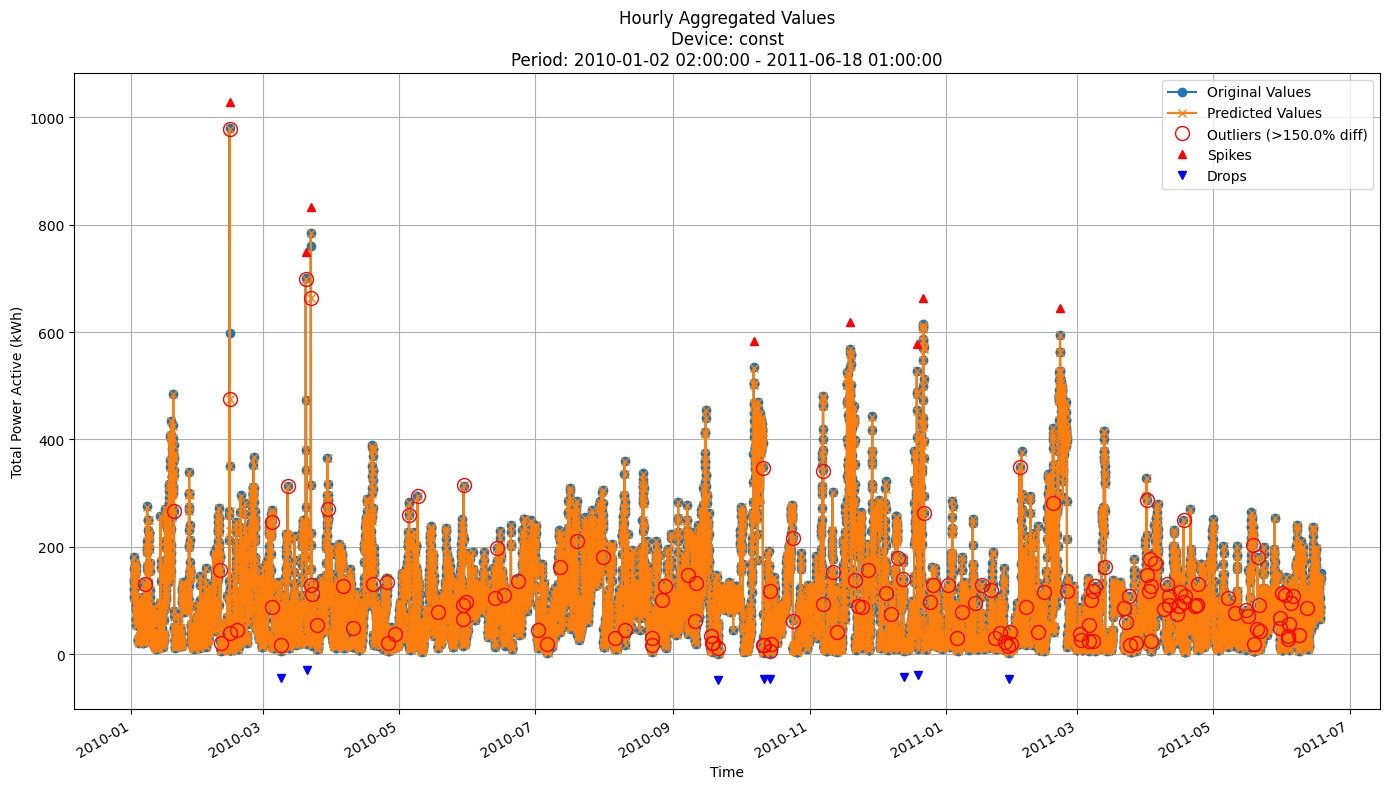


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 27.5487
MAE: 13.5763
MAPE: 20.8680%

Directional Metrics:
Directional Accuracy: 51.5980%
First-Diff Correlation: -0.0397

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 0.8889
  Recall: 1.0000
  F1 Score: 0.9412


In [18]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)
# 0.17, 0.12, 25.55, 70.81%, 0.72

#### Validation plots
Plot only the last few periods of predictions

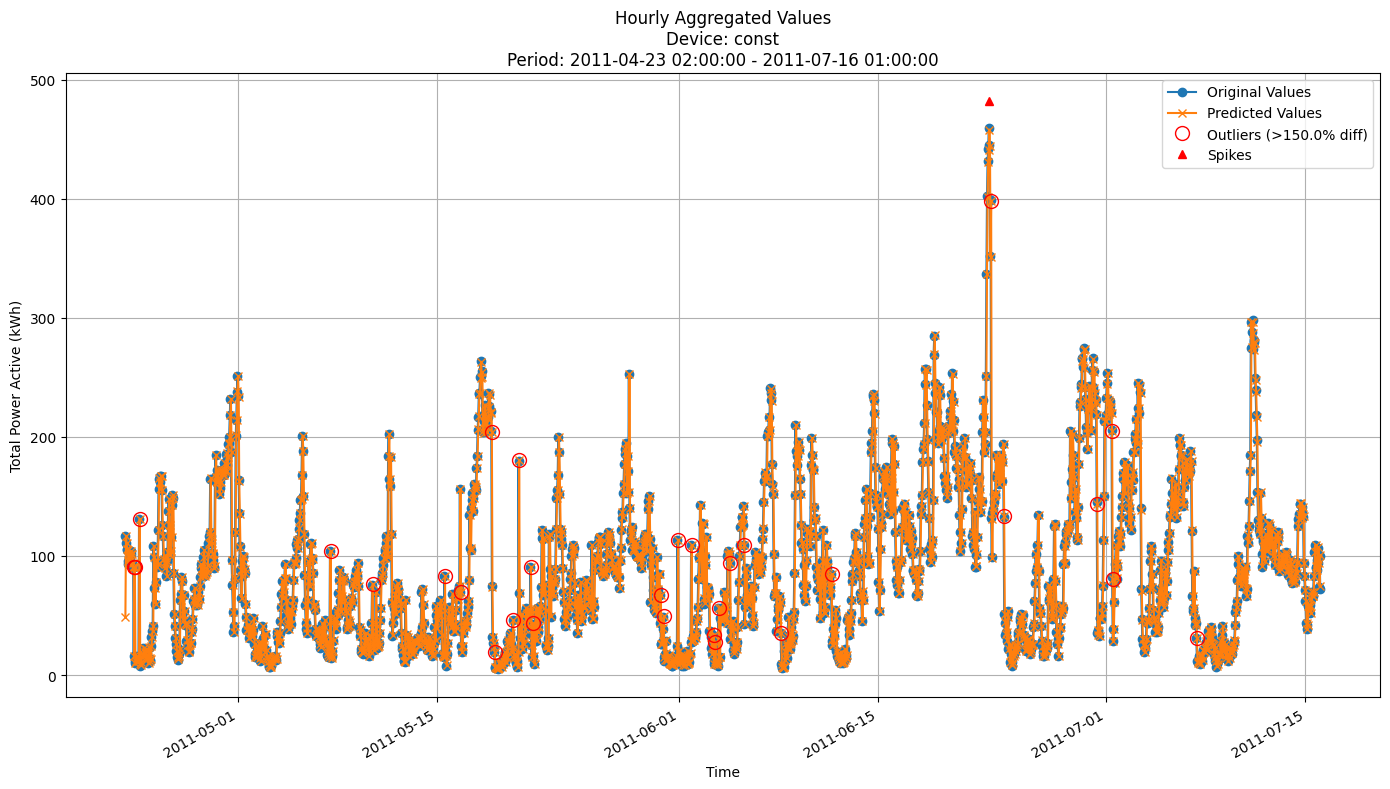


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 21.3898
MAE: 12.7046
MAPE: 21.6647%

Directional Metrics:
Directional Accuracy: 50.8685%
First-Diff Correlation: 0.0216

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [19]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

# Basic Prediction Metrics:
# RMSE: 0.2195
# MAE: 0.1398
# MAPE: 33.6987%

### Random Forest model

In [20]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor
rf_params = {'n_estimators': 300, 
             'max_depth': 3,
             'max_features': 0.3, 
             'random_state': 42, 
             'n_jobs': -1}

In [21]:
rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=rf, 
    model_params=rf_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/19 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2010-01-02 02:00:00+01:00 to 2010-01-30 00:00:00+01:00

Time: 0.34 seconds
Predicting for chunk from 2010-01-30 01:00:00+01:00 to 2010-02-13 01:00:00+01:00

-------------------------

Retraining model on data from 2010-01-02 02:00:00+01:00 to 2010-02-13 01:00:00+01:00

Time: 0.30 seconds
Predicting for chunk from 2010-02-13 02:00:00+01:00 to 2010-02-27 00:00:00+01:00

-------------------------
Model's memory usage: 0.119949 MB
Metrics for Device: const | Period: 2010-01-30 01:00:00+01:00 - 2010-02-27 00:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 54.1610
	MAE: 16.9742
	MAPE: 23.6653%

Directional Metrics:
	Directional Accuracy: 54.2474%
	First-Diff Correlation: -0.5371

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1429
		Recall: 0.1429
		F1: 0.1429
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (del

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2010-01-02 02:00:00+01:00 to 2010-02-27 00:00:00+01:00

Time: 0.30 seconds
Predicting for chunk from 2010-02-27 01:00:00+01:00 to 2010-03-13 01:00:00+01:00

-------------------------

Retraining model on data from 2010-01-02 02:00:00+01:00 to 2010-03-13 01:00:00+01:00

Time: 0.33 seconds
Predicting for chunk from 2010-03-13 02:00:00+01:00 to 2010-03-27 00:00:00+01:00

-------------------------
Model's memory usage: 0.119942 MB
Metrics for Device: const | Period: 2010-02-27 01:00:00+01:00 - 2010-03-27 00:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 51.7471
	MAE: 16.8786
	MAPE: 22.2008%

Directional Metrics:
	Directional Accuracy: 52.7571%
	First-Diff Correlation: -0.1310

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.1429
		Recall: 0.2000
		F1: 0.1667

Delayed Detection (del

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (29 outputs left out)

Processing devices in split 17:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2010-01-02 02:00:00+01:00 to 2011-05-21 01:00:00+02:00

Time: 0.38 seconds
Predicting for chunk from 2011-05-21 02:00:00+02:00 to 2011-06-04 02:00:00+02:00

-------------------------

Retraining model on data from 2010-01-02 02:00:00+01:00 to 2011-06-04 02:00:00+02:00

Time: 0.38 seconds
Predicting for chunk from 2011-06-04 03:00:00+02:00 to 2011-06-18 01:00:00+02:00

-------------------------
Model's memory usage: 0.119942 MB
Metrics for Device: const | Period: 2011-05-21 02:00:00+02:00 - 2011-06-18 01:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 19.9176
	MAE: 12.6921
	MAPE: 23.4305%

Directional Metrics:
	Directional Accuracy: 51.7139%
	First-Diff Correlation: -0.0616

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (del

Processing devices in split 18:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2010-01-02 02:00:00+01:00 to 2011-06-18 01:00:00+02:00

Time: 0.39 seconds
Predicting for chunk from 2011-06-18 02:00:00+02:00 to 2011-07-02 02:00:00+02:00

-------------------------

Retraining model on data from 2010-01-02 02:00:00+01:00 to 2011-07-02 02:00:00+02:00

Time: 0.45 seconds
Predicting for chunk from 2011-07-02 03:00:00+02:00 to 2011-07-16 01:00:00+02:00

-------------------------
Model's memory usage: 0.119942 MB
Metrics for Device: const | Period: 2011-06-18 02:00:00+02:00 - 2011-07-16 01:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 22.4900
	MAE: 13.3831
	MAPE: 16.0742%

Directional Metrics:
	Directional Accuracy: 50.9687%
	First-Diff Correlation: 0.1491

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delt

#### Results

In [22]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)

# Best values:
# Hourly Metrics:
# 	RMSE: 0.2221 ± 0.0148
# 	MAE: 0.1267 ± 0.0092
# 	MAPE: 22.1472% ± 2.0063%

# 	Directional Metrics:
# 		Directional Accuracy: 60.8511% ± 2.9815%
# 		First-Diff Correlation: 0.4859 ± 0.0565

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.2094 ± 0.0638
# 		Spike Recall: 0.1844 ± 0.0780
# 		Spike F1: 0.1927 ± 0.0741
# 		Drop Precision: 0.0547 ± 0.0125
# 		Drop Recall: 0.1408 ± 0.0536
# 		Drop F1: 0.0779 ± 0.0216

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4647 ± 0.0473
# 		Spike Recall: 0.3984 ± 0.1023
# 		Spike F1: 0.4191 ± 0.0799
# 		Drop Precision: 0.1104 ± 0.0172
# 		Drop Recall: 0.2821 ± 0.0884
# 		Drop F1: 0.1571 ± 0.0324



Train period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 29.4254 ± 3.9102
	MAE: 13.4854 ± 0.5047
	MAPE: 19.4944% ± 0.9982%

	Directional Metrics:
		Directional Accuracy: 53.0283% ± 0.3736%
		First-Diff Correlation: -0.0508 ± 0.0935

	Immediate Detection (delta=0):
		Spike Precision: 0.0107 ± 0.0223
		Spike Recall: 0.0100 ± 0.0206
		Spike F1: 0.0103 ± 0.0214
		Drop Precision: 0.0414 ± 0.0299
		Drop Recall: 0.0365 ± 0.0265
		Drop F1: 0.0388 ± 0.0281

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.9588 ± 0.0441
		Spike Recall: 0.9163 ± 0.0380
		Spike F1: 0.9368 ± 0.0387
		Drop Precision: 0.8932 ± 0.0540
		Drop Recall: 0.7895 ± 0.0528
		Drop F1: 0.8378 ± 0.0508
Daily Metrics:
	RMSE: 99.2949 ± 9.0727
	MAE: 70.8125 ± 6.0235
	MAPE: 4.0249% ± 0.6229%

	Directional Metrics:
		Directional Accuracy: 98.2956% ± 0.6279%
		First-Diff Correlation: 0.9962 ± 0.0006

	Immediate Detection (delta=0):
	

#### Training plots
Plot only the last period of predictions

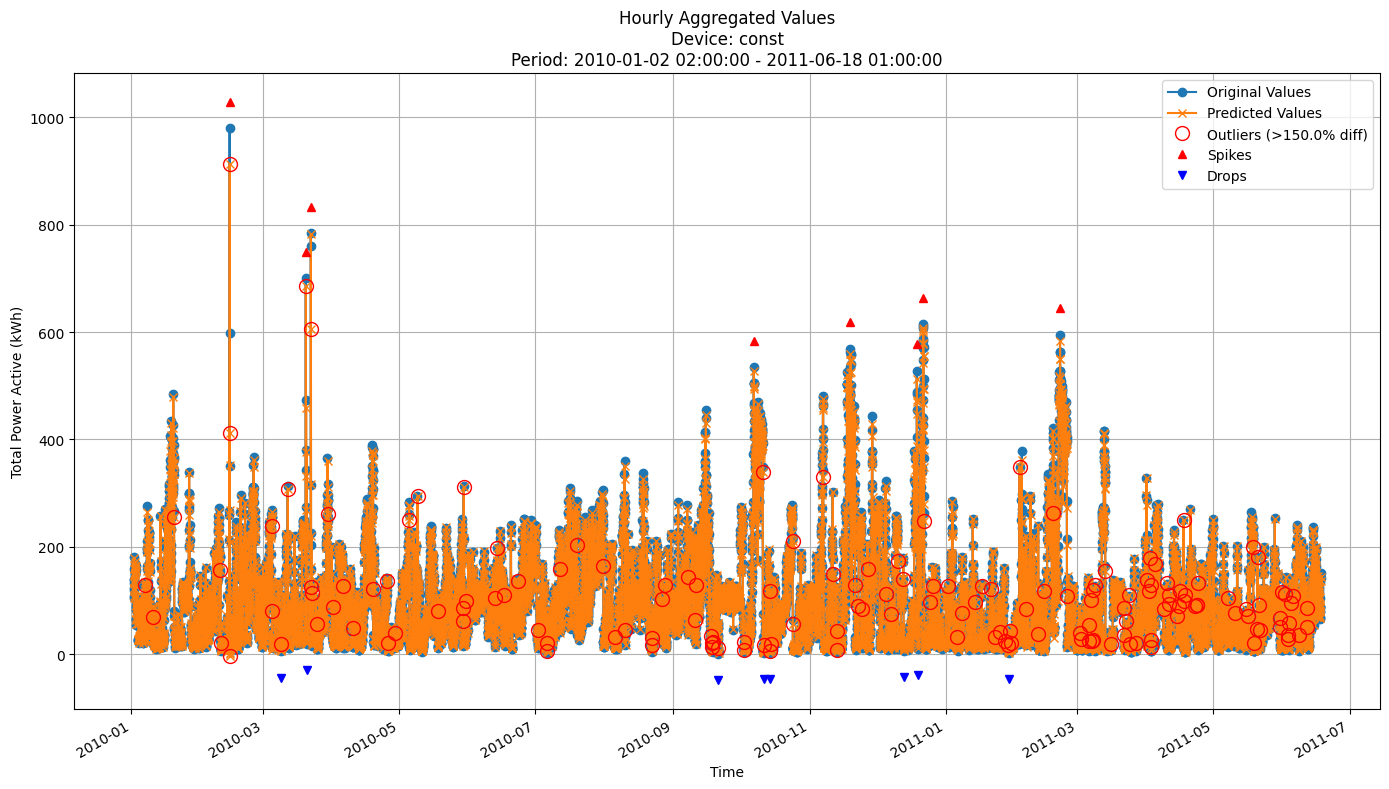


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 26.7735
MAE: 13.3490
MAPE: 21.0975%

Directional Metrics:
Directional Accuracy: 52.8592%
First-Diff Correlation: -0.0181

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8000
  Recall: 1.0000
  F1 Score: 0.8889
Drops:
  Precision: 0.6667
  Recall: 0.7500
  F1 Score: 0.7059


In [23]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last periods of predictions

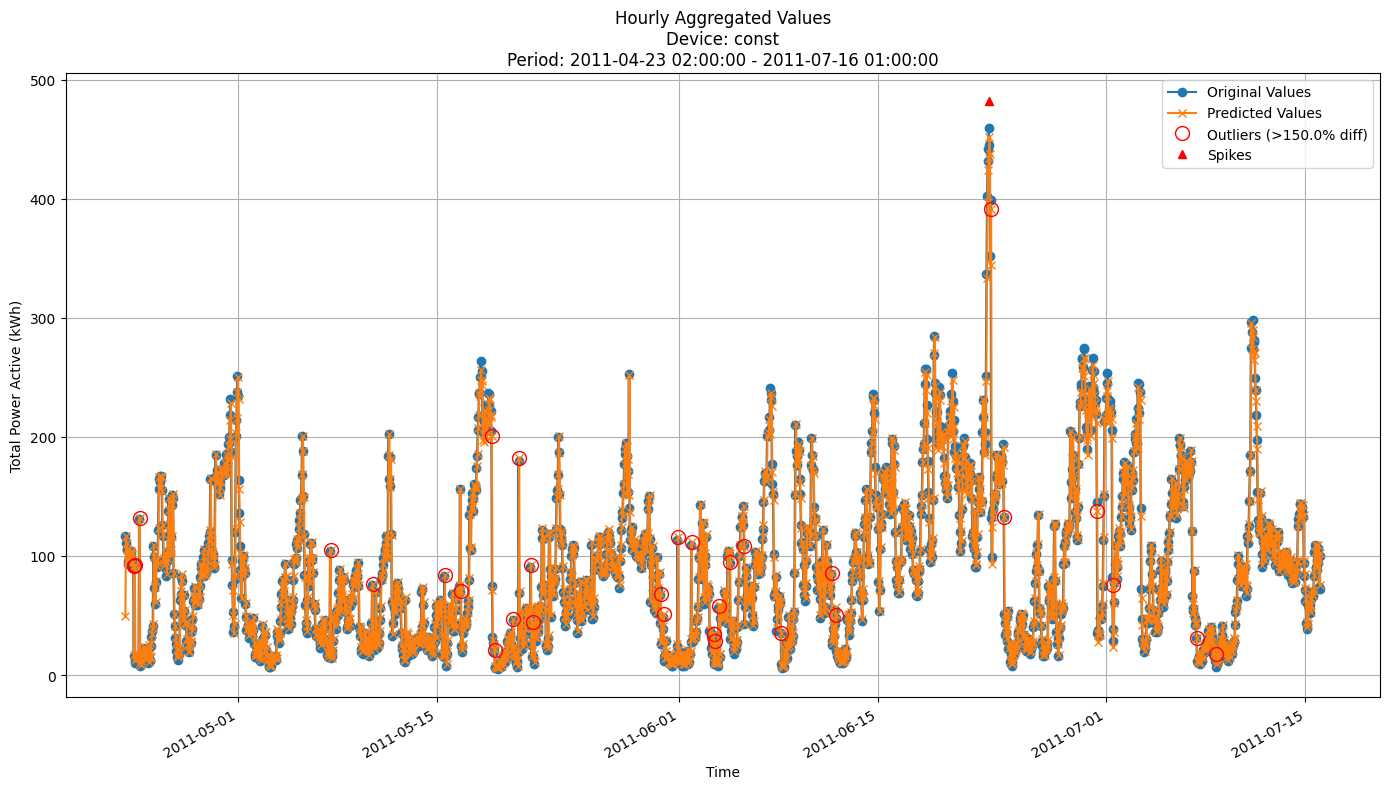


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 21.1130
MAE: 12.5276
MAPE: 21.8488%

Directional Metrics:
Directional Accuracy: 52.5558%
First-Diff Correlation: 0.0218

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [24]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in rf_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Hoeffding Tree

In [25]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

hoef = HoeffdingTreeRegressor
hoef_params = {'max_depth': 3, 
               'grace_period': 48, 
               'tau': 0.01, 
               'delta': 0.005}

In [26]:

hoef_all_train_preds, hoef_all_valid_preds, \
hoef_all_train_metrics, hoef_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=hoef, 
    model_params=hoef_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/19 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2010-01-30 00:00:00+01:00
Model's memory usage: 0.075317 MB
Metrics for Device: const | Period: 2010-01-30 01:00:00+01:00 - 2010-02-27 00:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 54.3730
	MAE: 16.9056
	MAPE: 24.3876%

Directional Metrics:
	Directional Accuracy: 54.2474%
	First-Diff Correlation: -0.5402

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1429
		Recall: 0.1429
		F1: 0.1429
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.8333
		Recall: 0.7143
		F1: 0.7692
-------------------------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2010-02-27 00:00:00+01:00
Model's memory usage: 0.074051 MB
Metrics for Device: const | Period: 2010-02-27 01:00:00+01:00 - 2010-03-27 00:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 51.0734
	MAE: 16.7220
	MAPE: 22.1076%

Directional Metrics:
	Directional Accuracy: 53.5022%
	First-Diff Correlation: -0.1205

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.1667
		Recall: 0.2000
		F1: 0.1818

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8571
		Recall: 1.0000
		F1: 0.9231
	Drops:
		Precision: 0.6667
		Recall: 0.8000
		F1: 0.7273
-------------------------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (29 outputs left out)

Processing devices in split 17:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2011-05-21 01:00:00+02:00
Model's memory usage: 0.072952 MB
Metrics for Device: const | Period: 2011-05-21 02:00:00+02:00 - 2011-06-18 01:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 20.0961
	MAE: 12.9563
	MAPE: 23.4221%

Directional Metrics:
	Directional Accuracy: 51.8629%
	First-Diff Correlation: -0.0597

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 0.4286
		F1: 0.6000
-------------------------------------------------

Processing devices in split 18:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2011-06-18 01:00:00+02:00
Model's memory usage: 0.072952 MB
Metrics for Device: const | Period: 2011-06-18 02:00:00+02:00 - 2011-07-16 01:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 22.9973
	MAE: 13.6346
	MAPE: 16.3022%

Directional Metrics:
	Directional Accuracy: 50.8197%
	First-Diff Correlation: 0.1482

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------

#### Results

In [27]:
print("\n\nTrain period metrics:")
hoef_all_time_train_metrics = all_time_aggregation_metrics(hoef_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
hoef_all_time_valid_metrics = all_time_aggregation_metrics(hoef_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 32.1657 ± 5.2957
	MAE: 14.0266 ± 0.5976
	MAPE: 20.2323% ± 1.0238%

	Directional Metrics:
		Directional Accuracy: 51.9234% ± 0.3330%
		First-Diff Correlation: -0.1421 ± 0.1226

	Immediate Detection (delta=0):
		Spike Precision: 0.0349 ± 0.0234
		Spike Recall: 0.0340 ± 0.0223
		Spike F1: 0.0345 ± 0.0228
		Drop Precision: 0.0401 ± 0.0328
		Drop Recall: 0.0386 ± 0.0326
		Drop F1: 0.0393 ± 0.0327

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.9833 ± 0.0230
		Spike Recall: 0.9637 ± 0.0296
		Spike F1: 0.9732 ± 0.0236
		Drop Precision: 0.8581 ± 0.0521
		Drop Recall: 0.8177 ± 0.0555
		Drop F1: 0.8372 ± 0.0526
Daily Metrics:
	RMSE: 109.2085 ± 12.2208
	MAE: 77.4340 ± 9.8934
	MAPE: 4.3801% ± 0.9636%

	Directional Metrics:
		Directional Accuracy: 97.0045% ± 2.0136%
		First-Diff Correlation: 0.9946 ± 0.0006

	Immediate Detection (delta=0):

#### Training plots
Plot only the last period of predictions

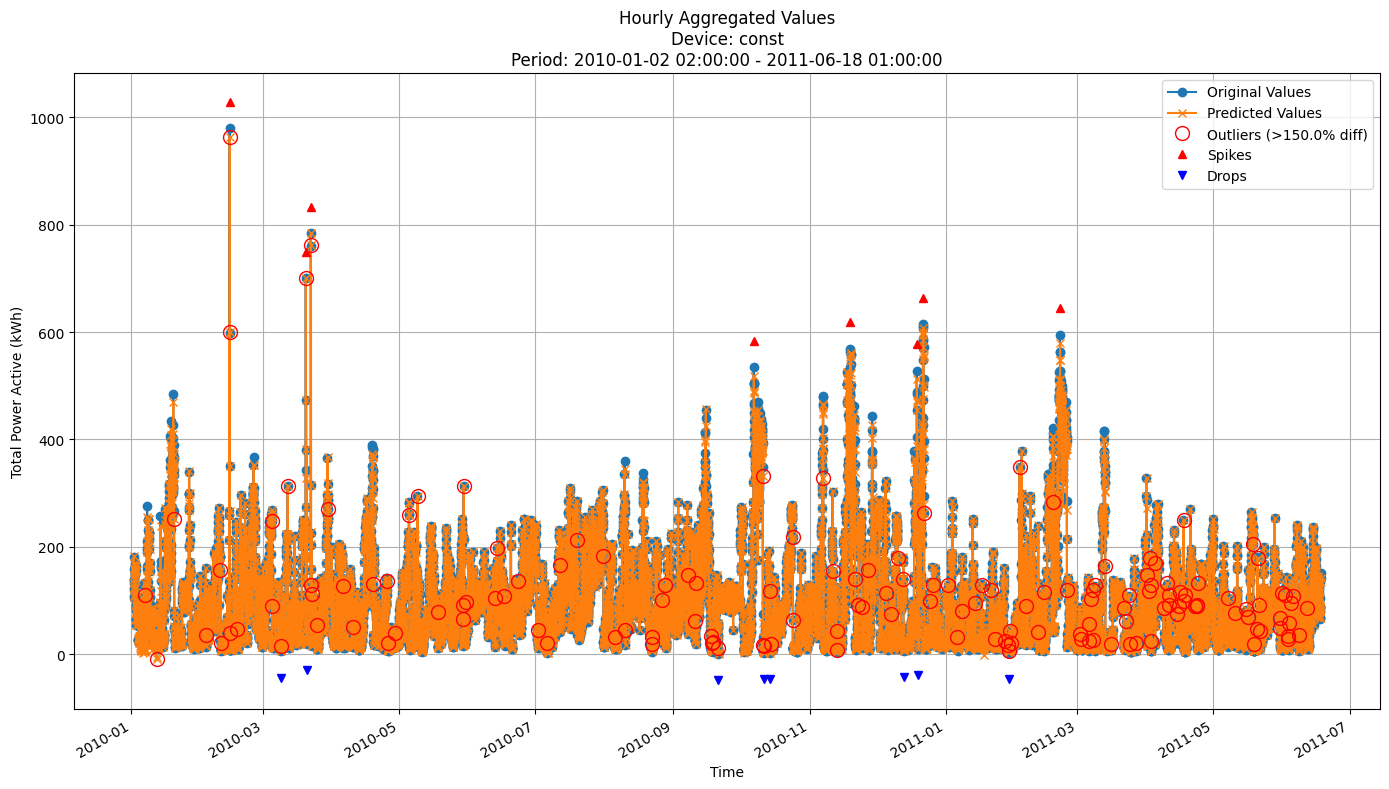


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 27.9059
MAE: 13.6399
MAPE: 21.2463%

Directional Metrics:
Directional Accuracy: 51.5510%
First-Diff Correlation: -0.0601

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7778
  Recall: 0.8750
  F1 Score: 0.8235
Drops:
  Precision: 0.7778
  Recall: 0.8750
  F1 Score: 0.8235


In [28]:
for device_id in hoef_all_train_preds.keys():
    y_train = hoef_all_train_preds[device_id][-1]['y_true']
    y_pred_train = hoef_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

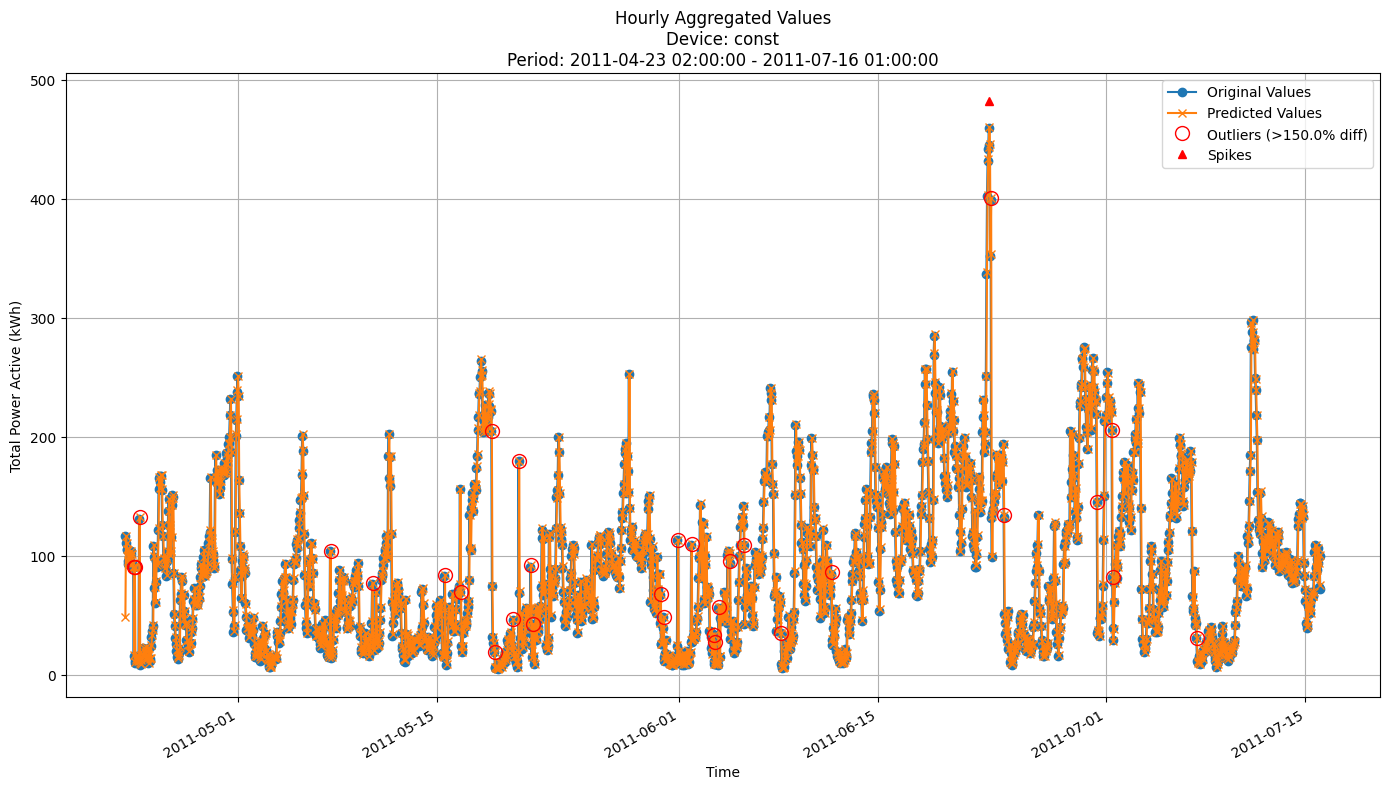


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 21.4272
MAE: 12.7289
MAPE: 21.8755%

Directional Metrics:
Directional Accuracy: 52.4566%
First-Diff Correlation: 0.0219

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [29]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in hoef_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (Hoeffding Tree)

In [ ]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf_hf = ARFRegressor
arf_hf_params = dict(n_models=10, 
                     max_features=0.8, 
                     aggregation_method='median', 
                     grace_period=10, 
                     max_depth=10, 
                     delta=0.5, 
                     tau=0.01, 
                     seed=42)  # NOT TUNED


In [31]:
arf_hf_all_train_preds, arf_hf_all_valid_preds, \
arf_hf_all_train_metrics, arf_hf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf_hf,
    model_params=arf_hf_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/19 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2010-01-30 00:00:00+01:00
Model's memory usage: 11.273575 MB
Metrics for Device: const | Period: 2010-01-30 01:00:00+01:00 - 2010-02-27 00:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 54.3128
	MAE: 16.8342
	MAPE: 24.1266%

Directional Metrics:
	Directional Accuracy: 53.9493%
	First-Diff Correlation: -0.5375

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.8571
		F1: 0.9231
	Drops:
		Precision: 0.8000
		Recall: 0.5714
		F1: 0.6667
------------------------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2010-02-27 00:00:00+01:00
Model's memory usage: 14.709137 MB
Metrics for Device: const | Period: 2010-02-27 01:00:00+01:00 - 2010-03-27 00:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 51.2645
	MAE: 16.7459
	MAPE: 22.0830%

Directional Metrics:
	Directional Accuracy: 53.3532%
	First-Diff Correlation: -0.1301

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.8000
		Recall: 0.8000
		F1: 0.8000
------------------------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (29 outputs left out)

Processing devices in split 17:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2011-05-21 01:00:00+02:00
Model's memory usage: 30.214745 MB
Metrics for Device: const | Period: 2011-05-21 02:00:00+02:00 - 2011-06-18 01:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 19.9300
	MAE: 12.7221
	MAPE: 23.8465%

Directional Metrics:
	Directional Accuracy: 52.0119%
	First-Diff Correlation: -0.0581

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 0.4286
		F1: 0.6000
------------------------------------------------

Processing devices in split 18:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2011-06-18 01:00:00+02:00
Model's memory usage: 30.480652 MB
Metrics for Device: const | Period: 2011-06-18 02:00:00+02:00 - 2011-07-16 01:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 22.8054
	MAE: 13.5331
	MAPE: 16.4142%

Directional Metrics:
	Directional Accuracy: 51.4158%
	First-Diff Correlation: 0.1480

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
-------------------------------------------------

#### Results

In [32]:
print("\n\nTrain period metrics:")
arf_hf_all_time_train_metrics = all_time_aggregation_metrics(arf_hf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_hf_all_time_valid_metrics = all_time_aggregation_metrics(arf_hf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 29.3250 ± 3.6374
	MAE: 13.2521 ± 0.3943
	MAPE: 19.4091% ± 0.9978%

	Directional Metrics:
		Directional Accuracy: 53.6612% ± 0.5443%
		First-Diff Correlation: -0.0400 ± 0.0725

	Immediate Detection (delta=0):
		Spike Precision: 0.0431 ± 0.0456
		Spike Recall: 0.0431 ± 0.0457
		Spike F1: 0.0431 ± 0.0456
		Drop Precision: 0.0825 ± 0.0505
		Drop Recall: 0.0763 ± 0.0492
		Drop F1: 0.0792 ± 0.0498

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.9386 ± 0.0323
		Spike Recall: 0.9259 ± 0.0381
		Spike F1: 0.9320 ± 0.0327
		Drop Precision: 0.8914 ± 0.0564
		Drop Recall: 0.8167 ± 0.0644
		Drop F1: 0.8518 ± 0.0570
Daily Metrics:
	RMSE: 99.7410 ± 7.3076
	MAE: 72.2836 ± 5.7888
	MAPE: 4.3357% ± 0.6055%

	Directional Metrics:
		Directional Accuracy: 98.3860% ± 0.4220%
		First-Diff Correlation: 0.9960 ± 0.0004

	Immediate Detection (delta=0):
	

#### Training plots

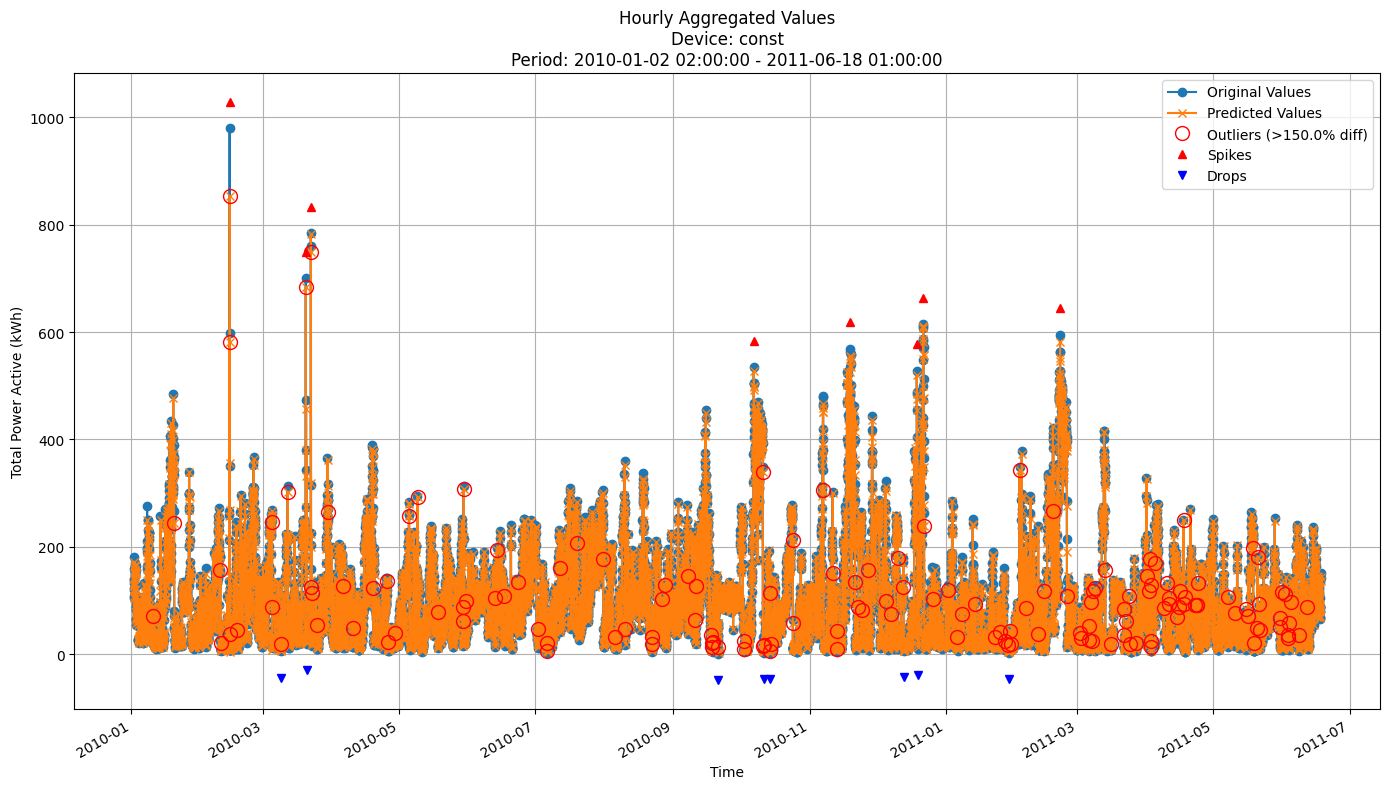


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 26.9458
MAE: 13.2183
MAPE: 21.2134%

Directional Metrics:
Directional Accuracy: 53.0942%
First-Diff Correlation: -0.0298

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 0.7500
  Recall: 0.7500
  F1 Score: 0.7500


In [33]:
for device_id in arf_hf_all_train_preds.keys():
    y_train = arf_hf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_hf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

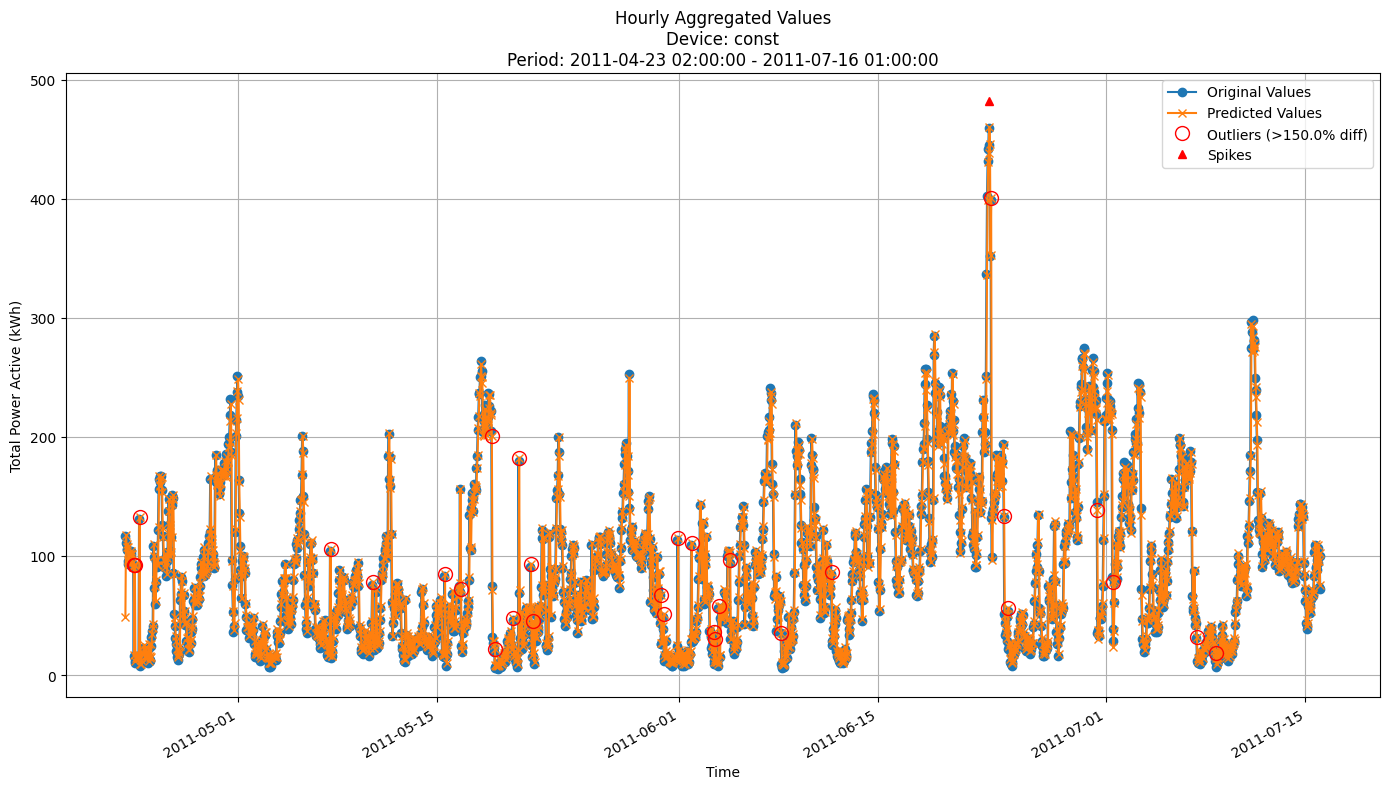


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 21.2406
MAE: 12.6182
MAPE: 22.3926%

Directional Metrics:
Directional Accuracy: 52.5558%
First-Diff Correlation: 0.0222

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [34]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_hf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### FastODT

In [35]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

fodt = fastodt.FastODT

fodt_params = {'depth': 10, 
               'grace_period': 96,
               'grace_period_depth': -1, 
               'split_confidence': 0.001, 
               'max_feature': 1.0, 
               'tie_threshold': 0.01, 
               'bin_type': 'adaptive', 
               'max_bins': 8, 
               'split_criterion': 'vr_rel'}

In [36]:
fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=fodt, 
    model_params=fodt_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/19 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2010-01-30 00:00:00+01:00
Model's memory usage: 0.066315 MB
Metrics for Device: const | Period: 2010-01-30 01:00:00+01:00 - 2010-02-27 00:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 54.3571
	MAE: 16.8615
	MAPE: 23.4059%

Directional Metrics:
	Directional Accuracy: 54.0984%
	First-Diff Correlation: -0.5406

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 0.8571
		F1: 0.9231
-------------------------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2010-02-27 00:00:00+01:00
Model's memory usage: 0.066917 MB
Metrics for Device: const | Period: 2010-02-27 01:00:00+01:00 - 2010-03-27 00:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 51.1743
	MAE: 16.7690
	MAPE: 21.8649%

Directional Metrics:
	Directional Accuracy: 53.5022%
	First-Diff Correlation: -0.1320

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
-------------------------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (29 outputs left out)

Processing devices in split 17:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2011-05-21 01:00:00+02:00
Model's memory usage: 0.069160 MB
Metrics for Device: const | Period: 2011-05-21 02:00:00+02:00 - 2011-06-18 01:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 20.0870
	MAE: 12.9192
	MAPE: 23.2286%

Directional Metrics:
	Directional Accuracy: 51.1177%
	First-Diff Correlation: -0.0600

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 0.4286
		F1: 0.6000
-------------------------------------------------

Processing devices in split 18:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2011-06-18 01:00:00+02:00
Model's memory usage: 0.069153 MB
Metrics for Device: const | Period: 2011-06-18 02:00:00+02:00 - 2011-07-16 01:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 23.0177
	MAE: 13.6691
	MAPE: 16.2823%

Directional Metrics:
	Directional Accuracy: 51.2668%
	First-Diff Correlation: 0.1482

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------

#### Results

In [37]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 32.3411 ± 5.3162
	MAE: 13.9548 ± 0.5703
	MAPE: 19.4543% ± 0.9371%

	Directional Metrics:
		Directional Accuracy: 51.5822% ± 0.3465%
		First-Diff Correlation: -0.1456 ± 0.1235

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 1.0000 ± 0.0000
		Spike Recall: 0.9956 ± 0.0141
		Spike F1: 0.9978 ± 0.0073
		Drop Precision: 1.0000 ± 0.0000
		Drop Recall: 0.9971 ± 0.0122
		Drop F1: 0.9985 ± 0.0063
Daily Metrics:
	RMSE: 99.7417 ± 8.2584
	MAE: 70.8214 ± 4.6770
	MAPE: 3.9708% ± 0.5295%

	Directional Metrics:
		Directional Accuracy: 98.0249% ± 0.6450%
		First-Diff Correlation: 0.9947 ± 0.0006

	Immediate Detection (delta=0):
	

#### Training plots


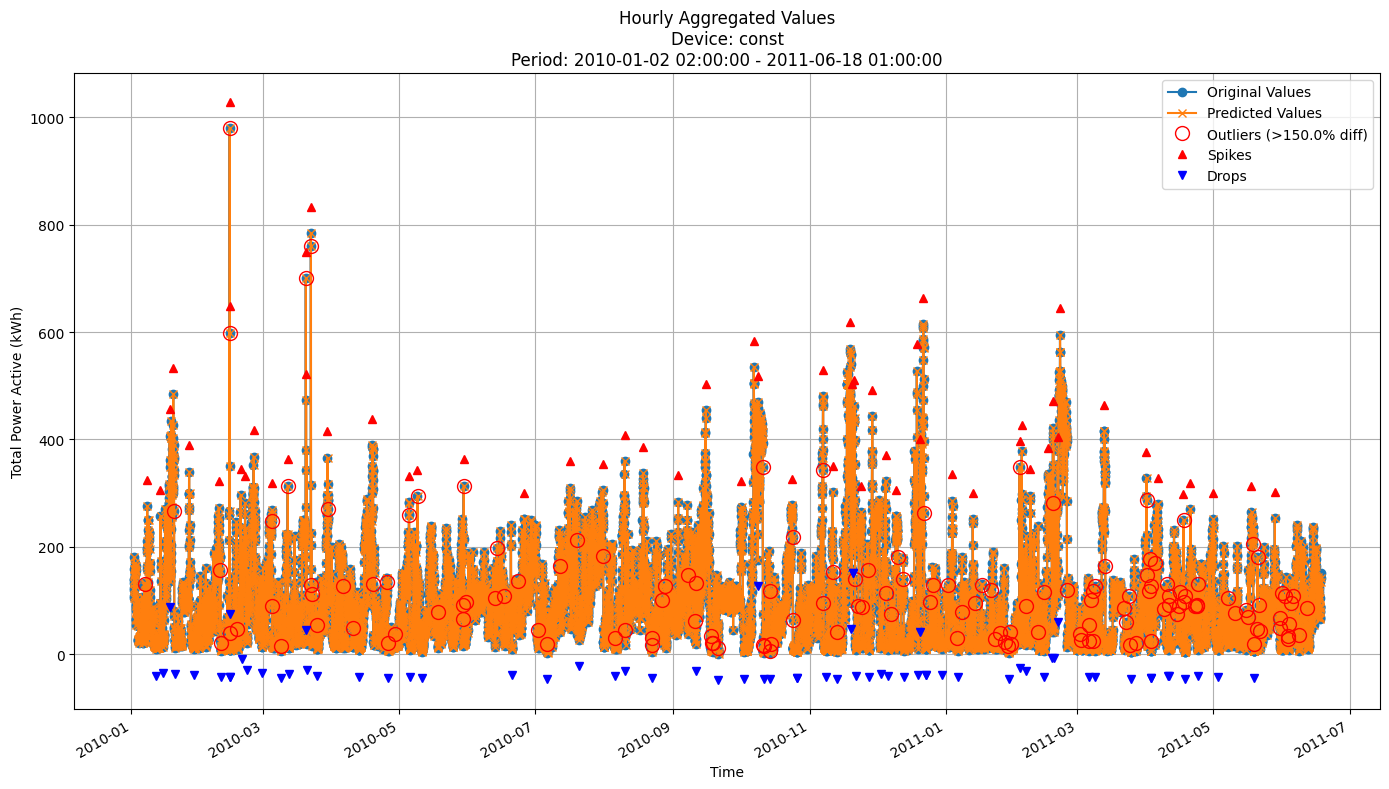


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 28.0362
MAE: 13.6346
MAPE: 20.8942%

Directional Metrics:
Directional Accuracy: 51.4413%
First-Diff Correlation: -0.0608

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


In [38]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id,
                            spike_prominence=SPIKE_PROMINENCE, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

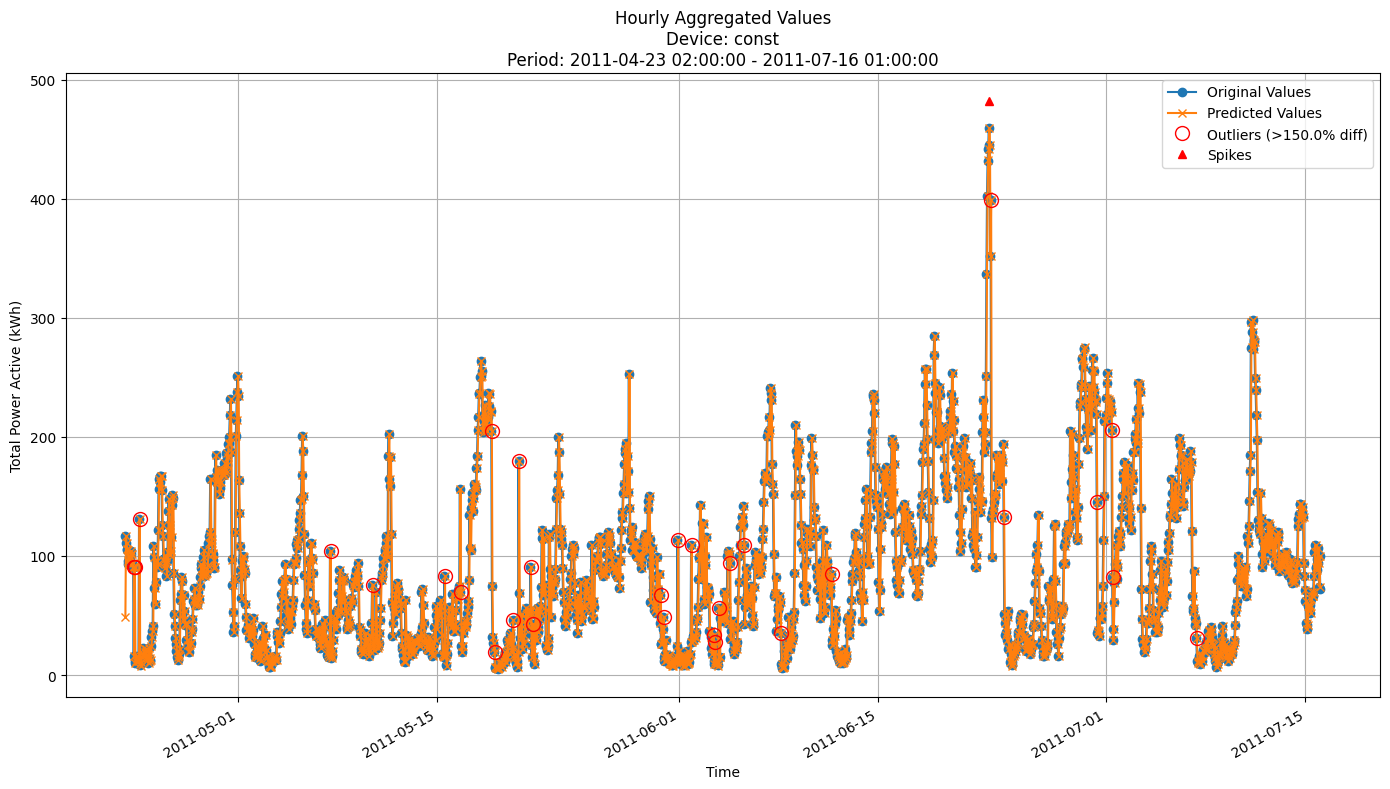


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 21.4373
MAE: 12.7341
MAPE: 21.6740%

Directional Metrics:
Directional Accuracy: 52.3573%
First-Diff Correlation: 0.0216

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [39]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in fodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (FastODT)

In [ ]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf = ARFRegressorFODT
arf_params = dict(n_models=20, 
                  aggregation_method="mean", 
                  grace_period=0,  # by default works for all leaves
                  disable_weighted_vote=True,
                  max_depth=10, 
                  delta=0.005, 
                  tau=0.01,
                  max_features=0.7, 
                  bin_type='adaptive', 
                  max_bins=8,
                  split_criterion='vr_rel',
                  seed=42, )  # NOT TUNED


In [41]:
arf_all_train_preds, arf_all_valid_preds, \
arf_all_train_metrics, arf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf,
    model_params=arf_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/19 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2010-01-30 00:00:00+01:00
Model's memory usage: 29.508247 MB
Metrics for Device: const | Period: 2010-01-30 01:00:00+01:00 - 2010-02-27 00:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 67.4940
	MAE: 18.7712
	MAPE: 25.4547%

Directional Metrics:
	Directional Accuracy: 53.8003%
	First-Diff Correlation: -0.5441

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1667
		Recall: 0.1429
		F1: 0.1538
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.8571
		F1: 0.9231
	Drops:
		Precision: 0.8000
		Recall: 0.5714
		F1: 0.6667
------------------------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2010-02-27 00:00:00+01:00
Model's memory usage: 62.454933 MB
Metrics for Device: const | Period: 2010-02-27 01:00:00+01:00 - 2010-03-27 00:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 52.0729
	MAE: 18.6892
	MAPE: 26.2460%

Directional Metrics:
	Directional Accuracy: 50.5216%
	First-Diff Correlation: -0.1298

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.3333
		Recall: 0.4000
		F1: 0.3636

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8571
		Recall: 1.0000
		F1: 0.9231
	Drops:
		Precision: 0.3333
		Recall: 0.4000
		F1: 0.3636
------------------------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (29 outputs left out)

Processing devices in split 17:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2011-05-21 01:00:00+02:00
Model's memory usage: 2.253647 MB
Metrics for Device: const | Period: 2011-05-21 02:00:00+02:00 - 2011-06-18 01:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 20.0721
	MAE: 12.9064
	MAPE: 23.2660%

Directional Metrics:
	Directional Accuracy: 51.1177%
	First-Diff Correlation: -0.0600

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 0.4286
		F1: 0.6000
-------------------------------------------------

Processing devices in split 18:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2011-06-18 01:00:00+02:00
Model's memory usage: 2.256142 MB
Metrics for Device: const | Period: 2011-06-18 02:00:00+02:00 - 2011-07-16 01:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 22.9642
	MAE: 13.6358
	MAPE: 16.2671%

Directional Metrics:
	Directional Accuracy: 51.1177%
	First-Diff Correlation: 0.1482

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------

#### Results

In [42]:
print("\n\nTrain period metrics:")
arf_all_time_train_metrics = all_time_aggregation_metrics(arf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_all_time_valid_metrics = all_time_aggregation_metrics(arf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 34.2106 ± 6.8253
	MAE: 15.4884 ± 2.1109
	MAPE: 22.5145% ± 3.8053%

	Directional Metrics:
		Directional Accuracy: 52.1448% ± 0.5520%
		First-Diff Correlation: -0.1050 ± 0.0956

	Immediate Detection (delta=0):
		Spike Precision: 0.0102 ± 0.0158
		Spike Recall: 0.0123 ± 0.0190
		Spike F1: 0.0111 ± 0.0172
		Drop Precision: 0.0319 ± 0.0369
		Drop Recall: 0.0369 ± 0.0424
		Drop F1: 0.0341 ± 0.0392

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8752 ± 0.1592
		Spike Recall: 0.9403 ± 0.0702
		Spike F1: 0.9035 ± 0.1196
		Drop Precision: 0.7158 ± 0.3010
		Drop Recall: 0.7053 ± 0.2391
		Drop F1: 0.7082 ± 0.2707
Daily Metrics:
	RMSE: 165.8354 ± 73.1878
	MAE: 100.6540 ± 33.9430
	MAPE: 5.6357% ± 1.8390%

	Directional Metrics:
		Directional Accuracy: 95.8564% ± 2.7099%
		First-Diff Correlation: 0.9840 ± 0.0132

	Immediate Detection (delta=0

#### Training plots

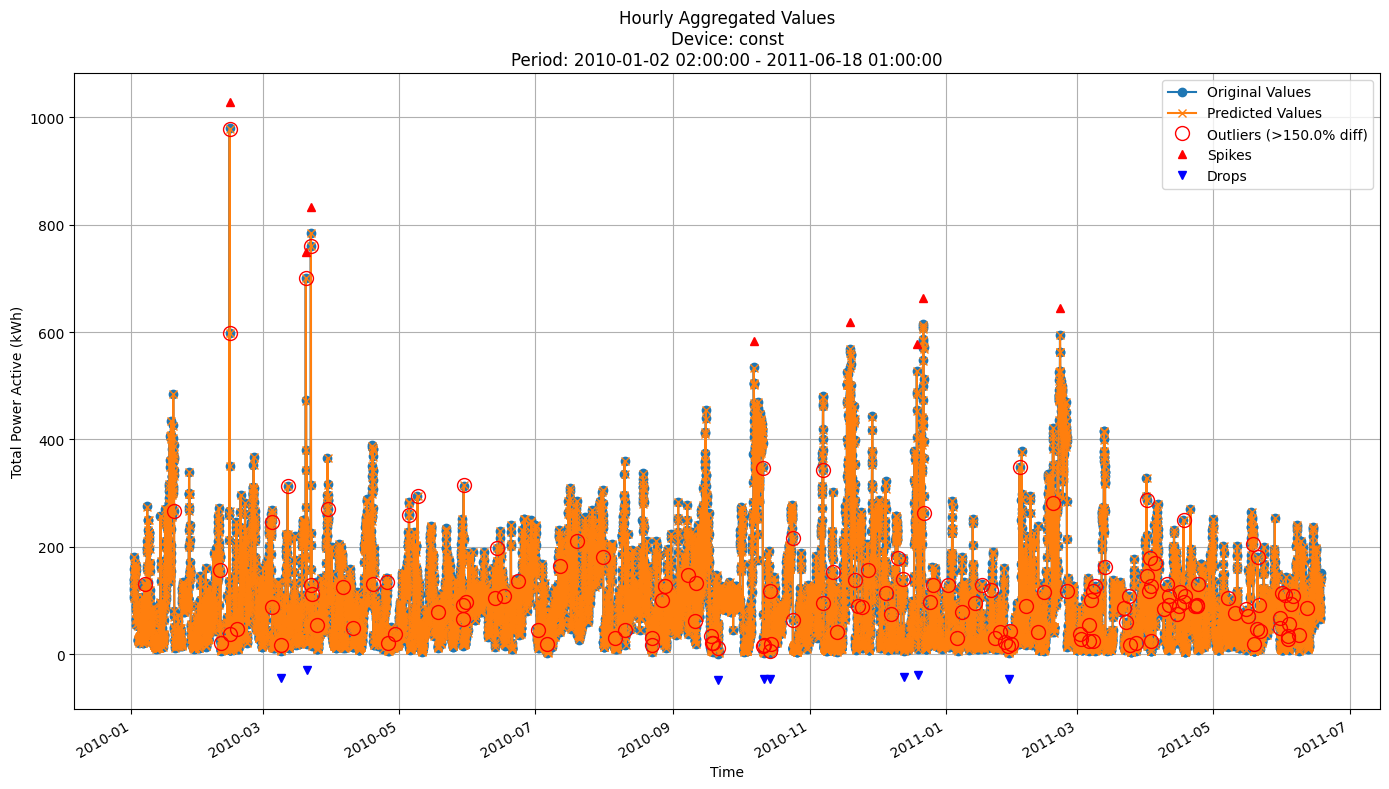


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 27.9979
MAE: 13.6165
MAPE: 20.9493%

Directional Metrics:
Directional Accuracy: 51.6293%
First-Diff Correlation: -0.0607

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8889
  Recall: 1.0000
  F1 Score: 0.9412
Drops:
  Precision: 0.7778
  Recall: 0.8750
  F1 Score: 0.8235


In [43]:
for device_id in arf_all_train_preds.keys():
    y_train = arf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

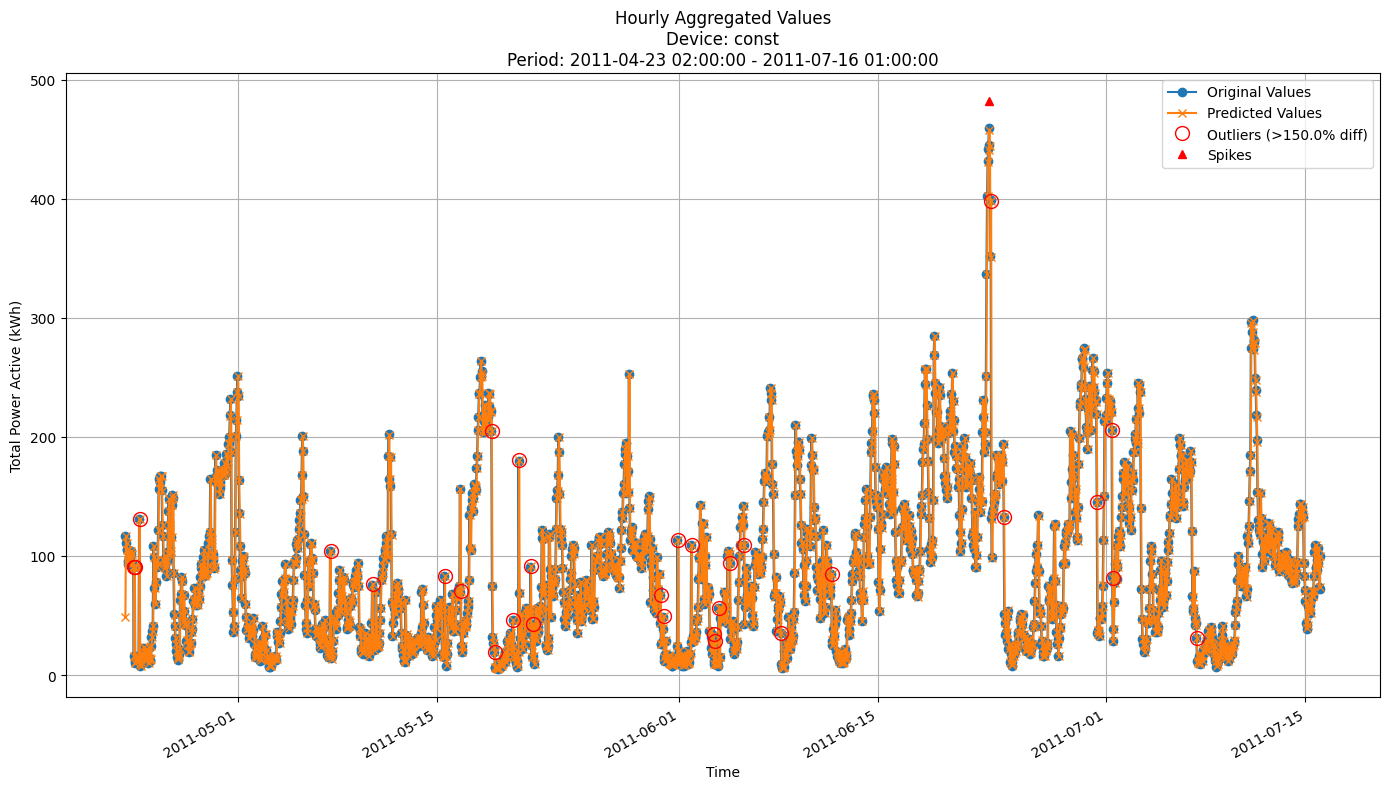


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 21.4081
MAE: 12.7205
MAPE: 21.7161%

Directional Metrics:
Directional Accuracy: 52.2581%
First-Diff Correlation: 0.0217

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [44]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost

In [45]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:

incb = IncubationBoost
incb_params = {'length': 40, 
               'learning_rate': 0.001, 
               'depth': 5, 
               'grace_period': 48, 
               'grace_period_depth': -1, 
               'split_confidence': 0.01, 
               'max_feature': 0.3, 
               'tie_threshold': 0.01, 
               'bin_type': 'adaptive', 
               'max_bins': 16, 
               'split_criterion': 'vr_rel', 
               'verbose': False}

In [46]:
incb_all_train_preds, incb_all_valid_preds, \
incb_all_train_metrics, incb_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=incb, 
    model_params=incb_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    # end_split=1,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/19 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2010-01-30 00:00:00+01:00
Model's memory usage: 0.105995 MB
Metrics for Device: const | Period: 2010-01-30 01:00:00+01:00 - 2010-02-27 00:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 54.3569
	MAE: 16.8541
	MAPE: 23.3972%

Directional Metrics:
	Directional Accuracy: 54.0984%
	First-Diff Correlation: -0.5406

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 0.8571
		F1: 0.9231
-------------------------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2010-02-27 00:00:00+01:00
Model's memory usage: 0.364372 MB
Metrics for Device: const | Period: 2010-02-27 01:00:00+01:00 - 2010-03-27 00:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 63.5657
	MAE: 19.5023
	MAPE: 24.7069%

Directional Metrics:
	Directional Accuracy: 52.4590%
	First-Diff Correlation: 0.0211

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.1429
		Recall: 0.2000
		F1: 0.1667

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7500
		Recall: 1.0000
		F1: 0.8571
	Drops:
		Precision: 0.2857
		Recall: 0.4000
		F1: 0.3333
--------------------------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (29 outputs left out)

Processing devices in split 17:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2011-05-21 01:00:00+02:00
Model's memory usage: 0.065865 MB
Metrics for Device: const | Period: 2011-05-21 02:00:00+02:00 - 2011-06-18 01:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 20.0869
	MAE: 12.9188
	MAPE: 23.2285%

Directional Metrics:
	Directional Accuracy: 51.8629%
	First-Diff Correlation: -0.0600

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 0.4286
		F1: 0.6000
-------------------------------------------------

Processing devices in split 18:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2011-06-18 01:00:00+02:00
Model's memory usage: 0.115593 MB
Metrics for Device: const | Period: 2011-06-18 02:00:00+02:00 - 2011-07-16 01:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 23.0178
	MAE: 13.6688
	MAPE: 16.2823%

Directional Metrics:
	Directional Accuracy: 51.7139%
	First-Diff Correlation: 0.1482

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------

#### Results

In [47]:
print("\n\nTrain period metrics:")
incb_all_time_train_metrics = all_time_aggregation_metrics(incb_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
incb_all_time_valid_metrics = all_time_aggregation_metrics(incb_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.4348 ± 0.1387
# 	MAE: 0.3140 ± 0.0869
# 	MAPE: 60.2407% ± 12.6513%
# 	Dir Accuracy: 57.2071% ± 2.1944%
# 	First-Diff Correlation: 0.3343 ± 0.0699



Train period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 32.2598 ± 5.2732
	MAE: 13.9426 ± 0.5596
	MAPE: 19.5733% ± 1.0039%

	Directional Metrics:
		Directional Accuracy: 51.5764% ± 0.3528%
		First-Diff Correlation: -0.1453 ± 0.1235

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0135 ± 0.0242
		Drop Recall: 0.0134 ± 0.0240
		Drop F1: 0.0134 ± 0.0241

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.9956 ± 0.0128
		Spike Recall: 0.9905 ± 0.0172
		Spike F1: 0.9929 ± 0.0099
		Drop Precision: 0.9796 ± 0.0459
		Drop Recall: 0.9612 ± 0.0533
		Drop F1: 0.9701 ± 0.0478
Daily Metrics:
	RMSE: 99.4241 ± 9.6591
	MAE: 70.2149 ± 6.4032
	MAPE: 3.9593% ± 0.6647%

	Directional Metrics:
		Directional Accuracy: 98.0249% ± 0.6450%
		First-Diff Correlation: 0.9950 ± 0.0007

	Immediate Detection (delta=0):
	

#### Train plots

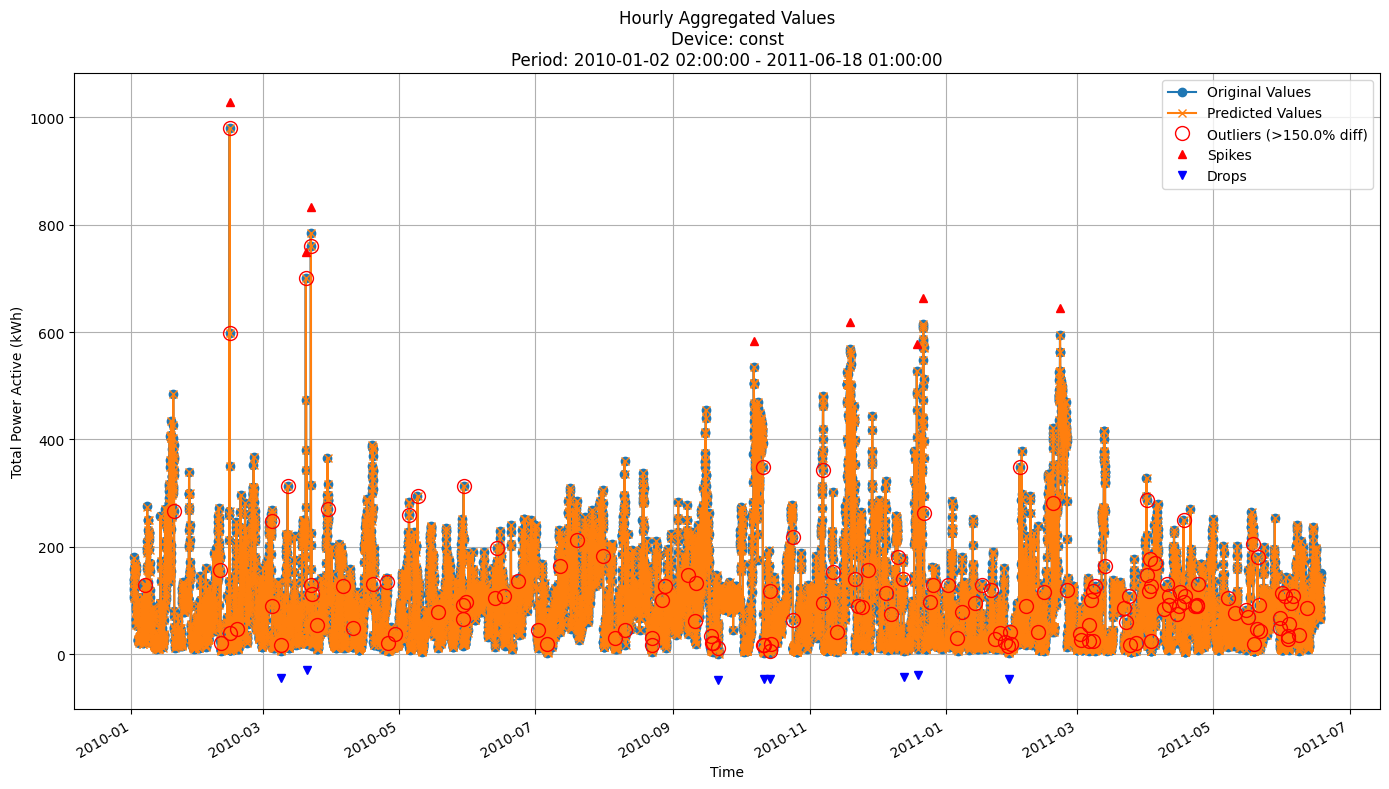


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 28.0349
MAE: 13.6345
MAPE: 20.8983%

Directional Metrics:
Directional Accuracy: 51.4413%
First-Diff Correlation: -0.0608

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


In [48]:
for device_id in incb_all_train_preds.keys():
    y_train = incb_all_train_preds[device_id][-1]['y_true']
    y_pred_train = incb_all_train_preds[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

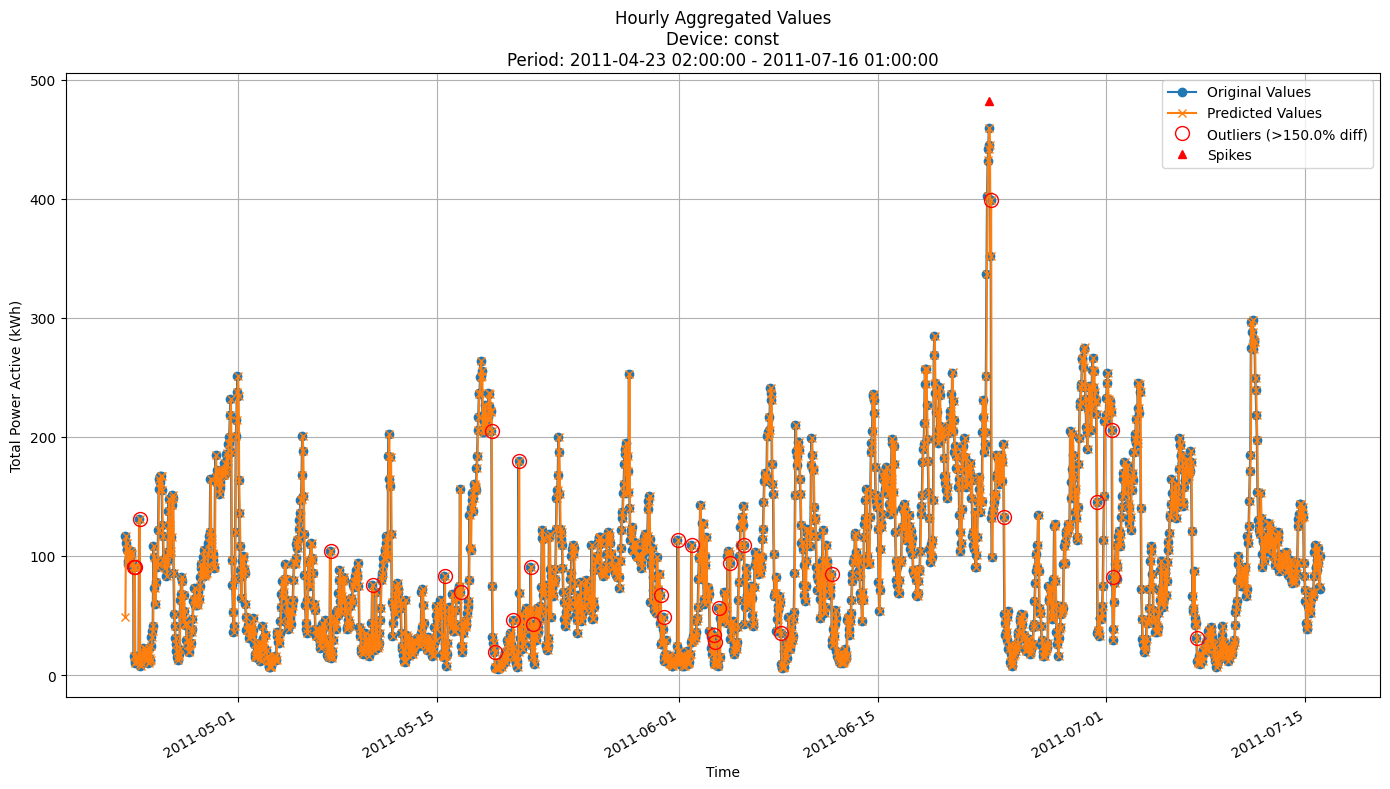


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 21.4373
MAE: 12.7338
MAPE: 21.6743%

Directional Metrics:
Directional Accuracy: 52.7543%
First-Diff Correlation: 0.0216

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [49]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in incb_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

## iNcubation Boost (elastic pruning)

In [50]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:

elastic = IncubationBoostElastic
elastic_params = {'length': 40, 
                  'learning_rate': 0.001, 
                  'depth': 5, 
                  'grace_period': 48, 
                  'grace_period_depth': -1, 
                  'split_confidence': 0.01, 
                  'max_feature': 0.3, 
                  'tie_threshold': 0.01, 
                  'bin_type': 'adaptive', 
                  'max_bins': 16, 
                  'split_criterion': 'vr_rel', 
                  'verbose': False}

In [51]:
elastic_all_train_preds, elastic_all_valid_preds, \
elastic_all_train_metrics, elastic_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=elastic, 
    model_params=elastic_params,
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    # end_split=1,  # Use only the third and fourth splits
    verbose=1)

Processing splits:   0%|          | 0/19 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2010-01-30 00:00:00+01:00
Model's memory usage: 0.063278 MB
Metrics for Device: const | Period: 2010-01-30 01:00:00+01:00 - 2010-02-27 00:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 54.3569
	MAE: 16.8541
	MAPE: 23.3972%

Directional Metrics:
	Directional Accuracy: 54.0984%
	First-Diff Correlation: -0.5406

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 0.8571
		F1: 0.9231
-------------------------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2010-02-27 00:00:00+01:00
Model's memory usage: 0.063591 MB
Metrics for Device: const | Period: 2010-02-27 01:00:00+01:00 - 2010-03-27 00:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 51.1742
	MAE: 16.7642
	MAPE: 21.8623%

Directional Metrics:
	Directional Accuracy: 52.9061%
	First-Diff Correlation: -0.1320

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
-------------------------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (29 outputs left out)

Processing devices in split 17:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2011-05-21 01:00:00+02:00
Model's memory usage: 0.128212 MB
Metrics for Device: const | Period: 2011-05-21 02:00:00+02:00 - 2011-06-18 01:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 20.0869
	MAE: 12.9188
	MAPE: 23.2285%

Directional Metrics:
	Directional Accuracy: 51.8629%
	First-Diff Correlation: -0.0600

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 0.4286
		F1: 0.6000
-------------------------------------------------

Processing devices in split 18:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2011-06-18 01:00:00+02:00
Model's memory usage: 0.116341 MB
Metrics for Device: const | Period: 2011-06-18 02:00:00+02:00 - 2011-07-16 01:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 23.0177
	MAE: 13.6688
	MAPE: 16.2823%

Directional Metrics:
	Directional Accuracy: 51.7139%
	First-Diff Correlation: 0.1482

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------

### Results

In [52]:
print("\n\nTrain period metrics:")
elastic_all_time_train_metrics = all_time_aggregation_metrics(elastic_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
elastic_all_time_valid_metrics = all_time_aggregation_metrics(elastic_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 32.2965 ± 5.2854
	MAE: 13.9652 ± 0.5762
	MAPE: 19.4980% ± 0.9146%

	Directional Metrics:
		Directional Accuracy: 51.6129% ± 0.3492%
		First-Diff Correlation: -0.1450 ± 0.1232

	Immediate Detection (delta=0):
		Spike Precision: 0.0067 ± 0.0197
		Spike Recall: 0.0063 ± 0.0183
		Spike F1: 0.0065 ± 0.0189
		Drop Precision: 0.0040 ± 0.0130
		Drop Recall: 0.0042 ± 0.0137
		Drop F1: 0.0041 ± 0.0133

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.9919 ± 0.0238
		Spike Recall: 0.9801 ± 0.0496
		Spike F1: 0.9857 ± 0.0368
		Drop Precision: 0.9717 ± 0.0592
		Drop Recall: 0.9627 ± 0.0701
		Drop F1: 0.9667 ± 0.0625
Daily Metrics:
	RMSE: 101.0528 ± 8.2693
	MAE: 71.2107 ± 4.7091
	MAPE: 3.9481% ± 0.5296%

	Directional Metrics:
		Directional Accuracy: 98.0323% ± 0.6445%
		First-Diff Correlation: 0.9949 ± 0.0007

	Immediate Detection (delta=0):


# Test-set Model Evaluation
(`train[-1]` + `valid[-1]`) vs `test`

In [53]:
# Define model classes and params for test-set evaluation
models_classes = [bl_prev, bl_mean, gbdt, rf, hoef, arf_hf, fodt, arf, incb, elastic]
models_params = [
    bl_prev_params,
    bl_mean_params,
    gbdt_params,
    rf_params,
    hoef_params,
    arf_hf_params,
    fodt_params,
    arf_params,
    incb_params,
    elastic_params
]

model_test_results = {}
for model_class, params in zip(models_classes, models_params):
    if model_class in [gbdt, rf, bl_mean]:
        incremental = False
        update_freq = "14D"
        print(f"Model: {model_class.__name__} - update_freq: {update_freq}")
    else:
        incremental = True
        update_freq = "1h"
        print(f"Model: {model_class.__name__} - update_freq: {update_freq}")

    _, test_preds, \
    _, test_metrics = test_set_seq_fit_predict(
        model_class=model_class,
        model_params=params,
        train=train,
        valid=valid,
        test=test,
        use_residuals=USE_RESIDUAL,
        incremental=incremental,
        data_freq=DATA_FREQUENCY,
        forecast_horizon=FORECAST_HORIZON,
        features=ALL_FEATURES,
        update_freq=update_freq,
        spike_prominence=SPIKE_PROMINENCE,
        normalize_robust=True,
        predict_train=False,
        verbose=True
    )
    model_test_results[model_class.__name__] = {
        "test_preds": test_preds,
        "test_metrics": test_metrics
    }

Model: PreviousValueRegressor - update_freq: 1h


Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2011-07-16 01:00:00+02:00
Model's memory usage: 0.000366 MB
Metrics for Device: const | Period: 2011-08-08 02:00:00+02:00 - 2011-12-31 22:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 25.8998
	MAE: 14.1615
	MAPE: 20.2540%

Directional Metrics:
	Directional Accuracy: 50.8997%
	First-Diff Correlation: 0.1770

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2010-01-02 02:00:00+01:00 to 2011-07-16 01:00:00+02:00

Time: 0.01 seconds
Predicting for chunk from 2011-08-08 02:00:00+02:00 to 2011-08-22 02:00:00+02:00

-------------------------

Retraining model on data from 2010-01-02 02:00:00+01:00 to 2011-08-22 02:00:00+02:00

Time: 0.01 seconds
Predicting for chunk from 2011-08-22 03:00:00+02:00 to 2011-09-05 03:00:00+02:00

-------------------------

Retraining model on data from 2010-01-02 02:00:00+01:00 to 2011-09-05 03:00:00+02:00

Time: 0.01 seconds
Predicting for chunk from 2011-09-05 04:00:00+02:00 to 2011-09-19 04:00:00+02:00

-------------------------

Retraining model on data from 2010-01-02 02:00:00+01:00 to 2011-09-19 04:00:00+02:00

Time: 0.01 seconds
Predicting for chunk from 2011-09-19 05:00:00+02:00 to 2011-10-03 05:00:00+02:00

-------------------------

Retraining model on data from 2010-01-02 02:00:00+01:00 to 2011-10-03 05:00:00+02:00

Time: 0.01 seconds
Predicting for chunk from 2011-10-03 0

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

... (11 outputs left out)

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2011-07-16 01:00:00+02:00
Model's memory usage: 0.125725 MB
Metrics for Device: const | Period: 2011-08-08 02:00:00+02:00 - 2011-12-31 22:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 25.6590
	MAE: 14.1330
	MAPE: 20.4086%

Directional Metrics:
	Directional Accuracy: 52.4136%
	First-Diff Correlation: 0.1775

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.8182
		Recall: 0.6000
		F1: 0.6923
--------------------------------------------------

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 23
Filtered feature count: 23
Excluded lag features: None
Initial training on data from 2010-01-02 02:00:00+01:00 to 2011-07-16 01:00:00+02:00
Model's memory usage: 0.128098 MB
Metrics for Device: const | Period: 2011-08-08 02:00:00+02:00 - 2011-12-31 22:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 25.7200
	MAE: 14.1521
	MAPE: 20.4582%

Directional Metrics:
	Directional Accuracy: 52.2993%
	First-Diff Correlation: 0.1769

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.7273
		Recall: 0.5333
		F1: 0.6154
--------------------------------------------------

In [54]:
for model_class in models_classes:
    model_test_results[model_class.__name__]['test_metrics'] = all_time_aggregation_metrics(
        model_test_results[model_class.__name__]['test_metrics'],
        data_freq=DATA_FREQUENCY,
        verbose=False)

# Model Comparison

In [55]:
AGG_LEVEL = "hourly"
METRICS = ["rmse", "mae", "mape", "dir_accuracy", "first_diff_corr"]
PERC_METRICS = ["mape", "dir_accuracy", "first_diff_corr"]
# SPIKES_METRICS = ["spikes_immediate.precision", "spikes_immediate.recall", "spikes_immediate.f1",
#                   "spikes_delayed.precision", "spikes_delayed.recall", "spikes_delayed.f1",
#                   "drops_immediate.precision", "drops_immediate.recall", "drops_immediate.f1",
#                   "drops_delayed.precision", "drops_delayed.recall", "drops_delayed.f1"]
SPIKES_METRICS = ["spikes_immediate.f1", "spikes_delayed.f1",
                  "drops_immediate.f1", "drops_delayed.f1"]

METRICS.extend(SPIKES_METRICS)
PERC_METRICS.extend(SPIKES_METRICS)

## Test results

In [56]:
MODEL_TEST_METRICS = {
    "BL_Prev": model_test_results[bl_prev.__name__]["test_metrics"],
    "BL_Mean": model_test_results[bl_mean.__name__]["test_metrics"],
    "GBDT": model_test_results[gbdt.__name__]["test_metrics"],
    "RandomForest": model_test_results[rf.__name__]["test_metrics"],
    "HoeffdingTree": model_test_results[hoef.__name__]["test_metrics"],
    "ARF_Hoeffding": model_test_results[arf_hf.__name__]["test_metrics"],
    "FastODT": model_test_results[fodt.__name__]["test_metrics"],
    "ARF_FastODT": model_test_results[arf.__name__]["test_metrics"],
    "IncubationBoost": model_test_results[incb.__name__]["test_metrics"],
    "IncubationBoostElastic": model_test_results[elastic.__name__]["test_metrics"],
}

In [57]:
def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f} ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

def display_aggregated_results(model_metrics, device_ids, agg_level):
    for device_id in device_ids:
        rows = []
        for model, mdict in model_metrics.items():
            if device_id in mdict and agg_level in mdict[device_id]:
                vals = mdict[device_id][agg_level]
                row = [model]
                for m in METRICS:
                    is_perc = (m in PERC_METRICS)
                    row.append(format_metric(vals.get(m, None), is_perc=is_perc))
                rows.append(row)
        df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)",
                                         "Spikes Immediate F1 (%)", "Spikes Delayed F1 (%)", "Drops Immediate F1 (%)", "Drops Delayed F1 (%)"])
        print(f"\n\nDevice: {device_id} | Aggregation: {agg_level}")
        display(df)

In [58]:
device_ids = set()
for m in MODEL_TEST_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

print("\n\n============================Hourly Test Results============================")
display_aggregated_results(MODEL_TEST_METRICS, device_ids, AGG_LEVEL)



============================Hourly Test Results============================


Device: const | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,25.900 ± 0.000,14.161 ± 0.000,20.254 ± 0.000,50.900 ± 0.000,17.705 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,100.000 ± 0.000
1,BL_Mean,25.787 ± 0.000,14.251 ± 0.000,21.741 ± 0.000,53.356 ± 0.000,17.933 ± 0.000,0.000 ± 0.000,96.000 ± 0.000,14.815 ± 0.000,44.444 ± 0.000
2,GBDT,25.755 ± 0.000,14.103 ± 0.000,20.241 ± 0.000,51.300 ± 0.000,17.752 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,85.714 ± 0.000
3,RandomForest,25.291 ± 0.000,13.967 ± 0.000,20.545 ± 0.000,52.642 ± 0.000,17.872 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,53.846 ± 0.000
4,HoeffdingTree,25.486 ± 0.000,14.001 ± 0.000,20.371 ± 0.000,52.556 ± 0.000,17.547 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,7.692 ± 0.000,76.923 ± 0.000
5,ARF_Hoeffding,25.362 ± 0.000,13.962 ± 0.000,20.959 ± 0.000,52.071 ± 0.000,17.938 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,61.538 ± 0.000
6,FastODT,25.901 ± 0.000,14.162 ± 0.000,20.254 ± 0.000,52.842 ± 0.000,17.705 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,7.692 ± 0.000,84.615 ± 0.000
7,ARF_FastODT,25.828 ± 0.000,14.132 ± 0.000,20.294 ± 0.000,52.328 ± 0.000,17.717 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,69.231 ± 0.000
8,IncubationBoost,25.659 ± 0.000,14.133 ± 0.000,20.409 ± 0.000,52.414 ± 0.000,17.751 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,69.231 ± 0.000
9,IncubationBoostElastic,25.720 ± 0.000,14.152 ± 0.000,20.458 ± 0.000,52.299 ± 0.000,17.693 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,61.538 ± 0.000


## Validation results

In [59]:
MODEL_VALID_METRICS = {
    "BL_Prev": bl_prev_all_time_valid_metrics,
    "BL_Mean": bl_mean_all_time_valid_metrics,
    "GBDT": gbdt_all_time_valid_metrics,
    "RandomForest": rf_all_time_valid_metrics,
    "HoeffdingTree": hoef_all_time_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_time_valid_metrics,
    "FastODT": fodt_all_time_valid_metrics,
    "ARF_FastODT": arf_all_time_valid_metrics,
    "IncubationBoost": incb_all_time_valid_metrics,
    "IncubationBoostElastic": elastic_all_time_valid_metrics,
}


device_ids = set()
for m in MODEL_VALID_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)


print("\n\n============================Hourly Validation Results============================")
display_aggregated_results(MODEL_VALID_METRICS, device_ids, AGG_LEVEL)



============================Hourly Validation Results============================


Device: const | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,26.050 ± 10.204,13.649 ± 2.834,20.836 ± 3.825,51.400 ± 2.676,6.355 ± 20.864,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,89.474 ± 30.689
1,BL_Mean,26.739 ± 10.292,14.776 ± 3.025,25.365 ± 5.280,53.055 ± 2.981,6.318 ± 20.331,5.093 ± 12.292,78.201 ± 30.285,6.184 ± 8.547,35.767 ± 29.291
2,GBDT,26.011 ± 10.135,13.641 ± 2.831,20.837 ± 3.831,51.455 ± 2.681,6.451 ± 20.707,0.752 ± 3.190,99.595 ± 1.718,0.957 ± 4.060,88.185 ± 30.391
3,RandomForest,29.425 ± 3.910,13.485 ± 0.505,19.494 ± 0.998,53.028 ± 0.374,-5.082 ± 9.353,1.031 ± 2.141,93.684 ± 3.874,3.877 ± 2.807,83.777 ± 5.081
4,HoeffdingTree,25.983 ± 10.199,13.670 ± 2.829,21.161 ± 3.985,52.922 ± 2.619,6.253 ± 20.706,7.331 ± 22.720,93.054 ± 22.298,1.511 ± 4.577,72.936 ± 28.177
5,ARF_Hoeffding,25.768 ± 10.277,13.549 ± 2.772,21.561 ± 4.270,52.773 ± 2.335,6.479 ± 20.804,0.526 ± 2.233,87.206 ± 25.523,2.922 ± 7.158,74.283 ± 29.479
6,FastODT,26.053 ± 10.209,13.652 ± 2.835,20.838 ± 3.827,53.149 ± 2.441,6.355 ± 20.864,0.000 ± 0.000,99.415 ± 2.481,0.554 ± 2.350,84.497 ± 30.487
7,ARF_FastODT,31.879 ± 13.398,15.747 ± 3.904,23.428 ± 3.555,52.757 ± 2.424,3.945 ± 20.449,3.149 ± 10.320,83.345 ± 21.650,1.914 ± 8.120,54.273 ± 36.750
8,IncubationBoost,26.652 ± 12.036,13.778 ± 3.041,21.060 ± 3.942,52.992 ± 2.362,7.136 ± 20.382,0.000 ± 0.000,96.617 ± 11.440,1.431 ± 4.290,78.733 ± 31.929
9,IncubationBoostElastic,26.061 ± 10.205,13.680 ± 2.833,20.960 ± 3.755,53.032 ± 2.401,6.308 ± 20.835,0.000 ± 0.000,99.474 ± 2.233,0.000 ± 0.000,77.730 ± 35.862


### By-period validation results

In [60]:
MODEL_VALID_PERIOD_METRICS = {
    "BL_Mean": bl_prev_valid_period_metrics,
    "BL_Prev": bl_mean_valid_period_metrics,
    "GBDT": gbdt_valid_period_metrics,
    "RandomForest": rf_valid_period_metrics,
    "HoeffdingTree": hoef_all_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_valid_metrics,
    "FastODT": fodt_all_valid_metrics,
    "ARF_FastODT": arf_all_valid_metrics,
    "IncubationBoost": incb_all_valid_metrics,
}

def show_per_period_metric_tables(device_ids, MODEL_VALID_PERIOD_METRICS, AGG_LEVEL, metric_name, display_gain=True):
    """
    Display per-period metric tables and gain/drop tables for a given metric.
    Args:
        device_ids: List of device IDs to display metrics for.
        MODEL_VALID_PERIOD_METRICS: Dictionary containing model period metrics.
        AGG_LEVEL: Aggregation level (e.g., "hourly").
        metric_name: The name of the metric to display.
        display_gain: Whether to display gain/drop tables.
    """
    for device_id in device_ids:
        period_vals = {}
        n_periods = None
        for model, mdict in MODEL_VALID_PERIOD_METRICS.items():
                if metric_name in PERC_METRICS:
                    vals = [period[AGG_LEVEL][metric_name]*100 for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                else:
                    vals = [period[AGG_LEVEL][metric_name] for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                n_periods = len(vals)
        if not period_vals:
            continue

        df_metric = pd.DataFrame(period_vals)
        df_metric.index = [f"Period {i+1}" for i in range(n_periods)]
        df_metric['Agg. Per Period'] = df_metric.astype(float).mean(axis=1)

        metric_label = f"{metric_name.upper()} (%)" if metric_name in PERC_METRICS else metric_name.upper()
        print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL} | {metric_label} per period")
        display(df_metric)


        if display_gain:
            # Absolute gain/drop
            abs_gain = df_metric.astype(float).diff().iloc[1:]
            abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")
            abs_gain.index = [f"{df_metric.index[i]} - {df_metric.index[i-1]}" for i in range(1, len(df_metric))]
            print(f"\nAbsolute gain/drop in {metric_label}:")
            display(abs_gain)
            # Percentage gain/drop
            # pct_gain = df_metric.astype(float).pct_change().iloc[1:] * 100
            # pct_gain = pct_gain.applymap(lambda v: f"{v:.3f}")
            # pct_gain.index = abs_gain.index
            # print(f"\nPercentage gain/drop in {metric_label} (lower is better):")
            # display(pct_gain)

#### Directional accuracy (higher is better)


In [61]:
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="dir_accuracy",
    display_gain=True
)


Device: const | Aggregation: hourly | DIR_ACCURACY (%) per period


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,52.161,53.055,52.906,54.247,54.247,53.949,54.098,53.800,54.098,53.617889
Period 2,50.969,56.185,51.118,52.757,53.502,53.353,53.502,50.522,52.459,52.707444
Period 3,54.993,52.459,54.844,55.589,56.185,55.887,57.079,56.334,57.079,55.605444
Period 4,48.435,48.286,48.435,49.925,50.075,52.310,50.969,52.459,50.075,50.107667
Period 5,53.353,52.906,53.353,53.353,53.800,53.055,53.800,53.204,53.651,53.386111
Period 6,50.820,53.502,50.820,51.714,52.459,51.714,52.310,52.161,52.310,51.978889
Period 7,47.690,49.627,47.690,48.584,48.733,47.988,49.180,49.627,48.584,48.633667
Period 8,50.820,52.757,50.820,51.714,51.267,51.565,52.161,51.416,52.012,51.614667
Period 9,57.079,61.103,57.079,57.824,58.122,56.930,58.271,57.824,57.228,57.940000
Period 10,53.800,54.098,53.800,54.694,55.589,54.098,54.844,54.993,54.844,54.528889



Absolute gain/drop in DIR_ACCURACY (%):


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-1.192,3.130,-1.788,-1.490,-0.745,-0.596,-0.596,-3.278,-1.639,-0.910
Period 3 - Period 2,4.024,-3.726,3.726,2.832,2.683,2.534,3.577,5.812,4.620,2.898
Period 4 - Period 3,-6.558,-4.173,-6.409,-5.664,-6.110,-3.577,-6.110,-3.875,-7.004,-5.498
Period 5 - Period 4,4.918,4.620,4.918,3.428,3.725,0.745,2.831,0.745,3.576,3.278
Period 6 - Period 5,-2.533,0.596,-2.533,-1.639,-1.341,-1.341,-1.490,-1.043,-1.341,-1.407
Period 7 - Period 6,-3.130,-3.875,-3.130,-3.130,-3.726,-3.726,-3.130,-2.534,-3.726,-3.345
Period 8 - Period 7,3.130,3.130,3.130,3.130,2.534,3.577,2.981,1.789,3.428,2.981
Period 9 - Period 8,6.259,8.346,6.259,6.110,6.855,5.365,6.110,6.408,5.216,6.325
Period 10 - Period 9,-3.279,-7.005,-3.279,-3.130,-2.533,-2.832,-3.427,-2.831,-2.384,-3.411
Period 11 - Period 10,1.342,3.279,1.342,1.044,1.341,2.981,1.639,1.788,1.639,1.822


#### MAPE (lower is better)

In [62]:
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="mape",
    display_gain=True
)


Device: const | Aggregation: hourly | MAPE (%) per period


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,23.373,34.582,23.136,23.665,24.388,24.127,23.406,25.455,23.397,25.058778
Period 2,21.854,29.219,21.878,22.201,22.108,22.083,21.865,26.246,24.707,23.573444
Period 3,17.173,25.108,17.203,19.002,17.539,17.872,17.170,30.410,17.173,19.850000
Period 4,19.032,28.680,19.045,19.373,19.392,19.796,19.028,23.547,19.137,20.781111
Period 5,18.432,20.779,18.439,18.539,18.553,18.517,18.433,22.619,18.434,19.193889
Period 6,16.183,17.103,16.186,16.443,16.268,16.384,16.183,22.590,16.165,17.056111
Period 7,15.285,17.477,15.291,15.219,15.332,15.376,15.287,20.112,15.266,16.071667
Period 8,18.594,21.465,18.598,18.671,18.713,18.728,18.595,25.742,18.637,19.749222
Period 9,17.434,21.214,17.447,17.987,17.689,18.497,17.428,19.246,17.684,18.291778
Period 10,20.068,24.005,20.087,20.247,20.235,21.180,20.067,20.215,20.068,20.685778



Absolute gain/drop in MAPE (%):


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-1.519,-5.363,-1.258,-1.464,-2.280,-2.044,-1.541,0.791,1.310,-1.485
Period 3 - Period 2,-4.681,-4.111,-4.675,-3.199,-4.569,-4.211,-4.695,4.164,-7.534,-3.723
Period 4 - Period 3,1.859,3.572,1.842,0.371,1.853,1.924,1.858,-6.863,1.964,0.931
Period 5 - Period 4,-0.600,-7.901,-0.606,-0.834,-0.839,-1.279,-0.595,-0.928,-0.703,-1.587
Period 6 - Period 5,-2.249,-3.676,-2.253,-2.096,-2.285,-2.133,-2.250,-0.029,-2.269,-2.138
Period 7 - Period 6,-0.898,0.374,-0.895,-1.224,-0.936,-1.008,-0.896,-2.478,-0.899,-0.984
Period 8 - Period 7,3.309,3.988,3.307,3.452,3.381,3.352,3.308,5.630,3.371,3.678
Period 9 - Period 8,-1.160,-0.251,-1.151,-0.684,-1.024,-0.231,-1.167,-6.496,-0.953,-1.457
Period 10 - Period 9,2.634,2.791,2.640,2.260,2.546,2.683,2.639,0.969,2.384,2.394
Period 11 - Period 10,-0.101,0.447,-0.098,0.117,-0.062,-0.508,-0.100,-0.315,-0.165,-0.087


#### RMSE (lower is better)

In [63]:
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="rmse",
    display_gain=True
)


Device: const | Aggregation: hourly | RMSE per period


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,54.331,55.392,54.172,54.161,54.373,54.313,54.357,67.494,54.357,55.883333
Period 2,51.160,53.028,50.789,51.747,51.073,51.265,51.174,52.073,63.566,52.875000
Period 3,20.592,24.105,20.578,21.008,20.785,20.347,20.596,49.464,20.596,24.230111
Period 4,18.868,21.265,18.868,18.519,18.887,18.687,18.871,23.949,18.870,19.642667
Period 5,24.027,24.680,24.028,23.934,24.051,23.899,24.030,28.233,24.030,24.545778
Period 6,19.621,20.545,19.621,19.437,19.608,19.482,19.623,30.144,19.592,20.852556
Period 7,22.080,22.740,22.080,21.539,21.933,21.756,22.082,37.073,21.824,23.678556
Period 8,21.637,22.199,21.637,21.396,21.602,21.241,21.639,31.275,21.481,22.678556
Period 9,25.769,25.452,25.769,25.662,25.665,25.549,25.771,49.544,25.694,28.319444
Period 10,19.199,19.910,19.199,19.040,19.224,19.028,19.200,19.171,19.200,19.241222



Absolute gain/drop in RMSE:


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-3.171,-2.364,-3.383,-2.414,-3.300,-3.048,-3.183,-15.421,9.209,-3.008
Period 3 - Period 2,-30.568,-28.923,-30.211,-30.739,-30.288,-30.918,-30.578,-2.609,-42.970,-28.645
Period 4 - Period 3,-1.724,-2.840,-1.710,-2.489,-1.898,-1.660,-1.725,-25.515,-1.726,-4.587
Period 5 - Period 4,5.159,3.415,5.160,5.415,5.164,5.212,5.159,4.284,5.160,4.903
Period 6 - Period 5,-4.406,-4.135,-4.407,-4.497,-4.443,-4.417,-4.407,1.911,-4.438,-3.693
Period 7 - Period 6,2.459,2.195,2.459,2.102,2.325,2.274,2.459,6.929,2.232,2.826
Period 8 - Period 7,-0.443,-0.541,-0.443,-0.143,-0.331,-0.515,-0.443,-5.798,-0.343,-1.000
Period 9 - Period 8,4.132,3.253,4.132,4.266,4.063,4.308,4.132,18.269,4.213,5.641
Period 10 - Period 9,-6.570,-5.542,-6.570,-6.622,-6.441,-6.521,-6.571,-30.373,-6.494,-9.078
Period 11 - Period 10,9.162,8.469,9.162,8.577,8.623,8.356,9.163,9.081,8.821,8.824
